In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import os
import json
import geoplot
import pysal
from pysal.lib import weights
import mapclassify as mc
import rioxarray as rxr
import contextily as ctx
import rasterio
import rasterio.plot

Load the baronies and select only the ones in the four counties of interest. Also load the monumnets and clean up the data, remoning monumneats after 1600, those with 

In [3]:
baronies = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Baronies_-_OSi_National_Statutory_Boundaries_Generalised')
#baronies = baronies.to_crs(epsg=4326)
baronies.crs

<Projected CRS: EPSG:2157>
Name: IRENET95 / Irish Transverse Mercator
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Ireland - onshore. United Kingdom (UK) - Northern Ireland (Ulster) - onshore.
- bounds: (-10.56, 51.39, -5.34, 55.43)
Coordinate Operation:
- name: Irish Transverse Mercator
- method: Transverse Mercator
Datum: IRENET95
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [3]:
sites_nw = gpd.read_file('filtered_points_2.shp')
sites_nw.crs


<Projected CRS: EPSG:2157>
Name: IRENET95 / Irish Transverse Mercator
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Ireland - onshore. United Kingdom (UK) - Northern Ireland (Ulster) - onshore.
- bounds: (-10.56, 51.39, -5.34, 55.43)
Coordinate Operation:
- name: Irish Transverse Mercator
- method: Transverse Mercator
Datum: IRENET95
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [5]:
sites_nw.info()



<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 9842 entries, 0 to 9841
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OID_        9842 non-null   int64   
 1   OBJECTID    9842 non-null   int64   
 2   ENTITY_ID   9842 non-null   object  
 3   CLASS_CODE  9842 non-null   object  
 4   SMRS        9842 non-null   object  
 5   COUNTY      9842 non-null   object  
 6   TOWNLAND    9842 non-null   object  
 7   COUNTY_ID   9842 non-null   int64   
 8   ZONE_ID     9257 non-null   object  
 9   ITM_E       9842 non-null   int64   
 10  ITM_N       9842 non-null   int64   
 11  LATITUDE    9842 non-null   float64 
 12  LONGITUDE   9842 non-null   float64 
 13  MONUMENT_T  9842 non-null   object  
 14  FIRST_EDIT  3466 non-null   object  
 15  LATEST_EDI  7971 non-null   object  
 16  WEBSITE_LI  9842 non-null   object  
 17  WEB_NOTES   9842 non-null   object  
 18  geometry    9842 non-null   geometry
dty

<Axes: >

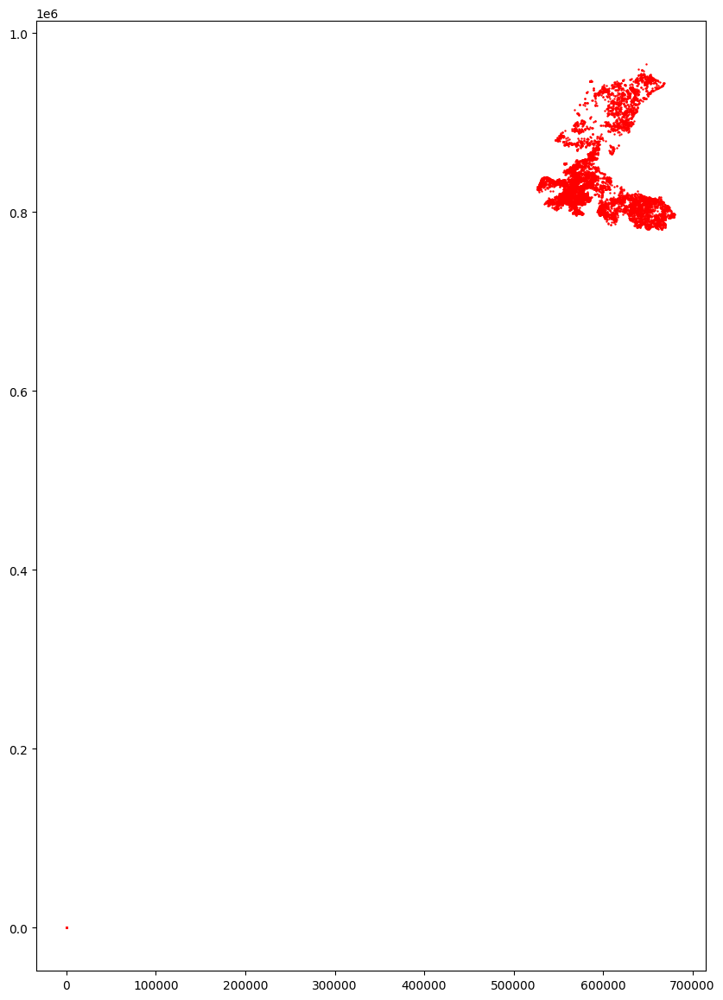

In [6]:
sites_nw.plot(figsize=(10,15), color='red', markersize=0.5)

# Sites with 0, 0 coordinates are showing up in the map. Remove them.

In [13]:
baronies.info

<bound method DataFrame.info of       BY_ID                       ENGLISH                           GAEILGE  \
0     39010                   TULLA LOWER              An Tulach Íochtarach   
1     49008  CARBERY WEST (West Division)  Cairbrigh Thiar (an Roinn Thiar)   
2    219014                     GLENAHIRY                 Gleann na hUidhre   
3    179005                        TROUGH                        An Triúcha   
4     79003               DUNKERRON NORTH               Dún Ciaráin Thuaidh   
..      ...                           ...                               ...   
275   69019                       MOYCARN                    Maigh Charnáin   
276  239013                 ATHLONE SOUTH            Baile Átha Luain Theas   
277   59006                  RAPHOE NORTH                Ráth Bhoth Thuaidh   
278   99003                    FASSADININ                Fásach an Deighnín   
279  119001                   CARRIGALLEN                    Carraig Álainn   

    LOGAINM_ID     

In [104]:
# selest all baronies where county is donegal sligo and leitrim and Cavan 
# Cavan may be suitable as a validation area

baronies_NW = baronies[baronies['COUNTY'].isin(['DONEGAL', 'SLIGO', 'LEITRIM', 'CAVAN'])]
#baronies_NW.info()
baronies_NW.head()
#baronies_NW.__class__


,BY_ID,ENGLISH,GAEILGE,LOGAINM_ID,CONTAE,COUNTY,PROVINCE,GUID,CENTROID_X,CENTROID_Y,AREA,OBJECTID,Shape__Are,Shape__Len,geometry
8,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,1.196357e+08,9,1.196164e+08,83423.562039,"POLYGON ((635676.603 810901.511, 635754.704 81..."
12,59008,TIRHUGH,Tír Aodha,52,Dún na nGall,DONEGAL,Ulster,2ae19629-11ec-13a3-e055-000000000001,599471.23,873654.18,5.197514e+08,13,5.197586e+08,200162.686389,"MULTIPOLYGON (((595713.002 881098.568, 596161...."
14,29006,TULLYHAW,Teallach Eathach,14,An Cabhán,CAVAN,Ulster,2ae19629-11bf-13a3-e055-000000000001,612880.97,824809.79,3.668798e+08,15,3.668524e+08,137096.318593,"POLYGON ((609239.298 818234.003, 609226.717 81..."
28,29005,TULLYGARVEY,Teallach Ghairbhíth,16,An Cabhán,CAVAN,Ulster,2ae19629-11be-13a3-e055-000000000001,652637.30,809620.67,2.424731e+08,29,2.424888e+08,120125.504347,"POLYGON ((652793.375 816391.884, 652909.766 81..."
42,119002,DRUMAHAIRE,Droim Dhá Thiar,137,Liatroim,LEITRIM,Connacht,2ae19629-111a-13a3-e055-000000000001,592206.80,829758.65,4.740572e+08,43,4.740812e+08,143658.292704,"POLYGON ((597990.378 818769.081, 596669.263 81..."


In [ ]:
# Attempted groupby to create territories

# Iochtar_Connacht = [baronies_NW[""]] [baronies_NW['SLIGO']]
# Iochtar_Connacht.__class__





In [6]:
baronies_NW.describe

<bound method NDFrame.describe of       BY_ID         ENGLISH              GAEILGE LOGAINM_ID        CONTAE  \
8     29004  LOUGHTEE LOWER  Lucht Tí Íochtarach         13     An Cabhán   
12    59008         TIRHUGH            Tír Aodha         52  Dún na nGall   
14    29006        TULLYHAW     Teallach Eathach         14     An Cabhán   
28    29005     TULLYGARVEY  Teallach Ghairbhíth         16     An Cabhán   
42   119002      DRUMAHAIRE      Droim Dhá Thiar        137      Liatroim   
83    29001     CASTLERAHAN     Caisleán Raithin         10     An Cabhán   
94    59005     KILMACRENAN    Cill Mhic Réanáin         55  Dún na nGall   
129  209003          CORRAN            An Corann        229      Sligeach   
134   29003       CLANMAHON       Clann Mhathúna          9     An Cabhán   
141   59001          BANAGH              Báinigh         54  Dún na nGall   
142  209002        COOLAVIN        Cúil Ó bhFinn        228      Sligeach   
144  119003         LEITRIM             Li

In [7]:
# Investigate the monuments file for the outliers showing up on the plot. 

sites_nw.info()
sites_nw.head()
#sites_nw.TOWNLAND.unique()
#sites_nw.TOWNLAND.nunique()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 9842 entries, 0 to 9841
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OID_        9842 non-null   int64   
 1   OBJECTID    9842 non-null   int64   
 2   ENTITY_ID   9842 non-null   object  
 3   CLASS_CODE  9842 non-null   object  
 4   SMRS        9842 non-null   object  
 5   COUNTY      9842 non-null   object  
 6   TOWNLAND    9842 non-null   object  
 7   COUNTY_ID   9842 non-null   int64   
 8   ZONE_ID     9257 non-null   object  
 9   ITM_E       9842 non-null   int64   
 10  ITM_N       9842 non-null   int64   
 11  LATITUDE    9842 non-null   float64 
 12  LONGITUDE   9842 non-null   float64 
 13  MONUMENT_T  9842 non-null   object  
 14  FIRST_EDIT  3466 non-null   object  
 15  LATEST_EDI  7971 non-null   object  
 16  WEBSITE_LI  9842 non-null   object  
 17  WEB_NOTES   9842 non-null   object  
 18  geometry    9842 non-null   geometry
dty

,OID_,OBJECTID,ENTITY_ID,CLASS_CODE,SMRS,COUNTY,TOWNLAND,COUNTY_ID,ZONE_ID,ITM_E,ITM_N,LATITUDE,LONGITUDE,MONUMENT_T,FIRST_EDIT,LATEST_EDI,WEBSITE_LI,WEB_NOTES,geometry
0,248,248,CV00251,UNCA,CV011-013009-,CAVAN,CORPORATION LANDS,3,R121602,0,0,46.488181,-15.817314,Castle - unclassified,NaN,NaN,https://maps.archaeology.ie/HistoricEnvironmen...,The Archaeological Survey of Ireland (ASI) is ...,POINT (0.000 0.000)
1,2325,2325,LE00212,BOCA,LE004-021----,LEITRIM,"CULLIONBOY,GUBINEA",16,NaN,584601,848442,54.384370,-8.237059,Cairn - boundary cairn,Not indicated,Pile of Stones,https://maps.archaeology.ie/HistoricEnvironmen...,Marked only on the 1910 ed. of the OS 6-inch m...,POINT (584601.000 848442.000)
2,5325,5325,LE00213,BOCA,LE004-022----,LEITRIM,"CULLIONBOY,GUBINEA",16,NaN,584582,848323,54.383300,-8.237346,Cairn - boundary cairn,Not indicated,Pile of Stones,https://maps.archaeology.ie/HistoricEnvironmen...,Marked only on the 1910 ed. of the OS 6-inch m...,POINT (584582.000 848323.000)
3,5326,5326,LE00214,BOCA,LE004-023----,LEITRIM,"LECKANARAINEY,CULLIONBOY",16,NaN,585017,848121,54.381498,-8.230639,Cairn - boundary cairn,Not indicated,Pile of Stones,https://maps.archaeology.ie/HistoricEnvironmen...,Marked only on the 1910 ed. of the OS 6-inch m...,POINT (585017.000 848121.000)
4,7588,7588,LE00215,BOCA,LE004-024----,LEITRIM,"LECKANARAINEY,MEENAGRAUN",16,NaN,585422,848309,54.383199,-8.224414,Cairn - boundary cairn,Not indicated,Pile of Stones,https://maps.archaeology.ie/HistoricEnvironmen...,Marked only on the 1910 ed. of the OS 6-inch m...,POINT (585422.000 848309.000)


In [8]:
sites_nw.columns



Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'geometry'],
      dtype='object')

In [9]:
baronies_NW.columns

Index(['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'CONTAE', 'COUNTY',
       'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID',
       'Shape__Are', 'Shape__Len', 'geometry'],
      dtype='object')

In [10]:
baronies_NW


,BY_ID,ENGLISH,GAEILGE,LOGAINM_ID,CONTAE,COUNTY,PROVINCE,GUID,CENTROID_X,CENTROID_Y,AREA,OBJECTID,Shape__Are,Shape__Len,geometry
8,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,1.196357e+08,9,1.196164e+08,83423.562039,"POLYGON ((635676.603 810901.511, 635754.704 81..."
12,59008,TIRHUGH,Tír Aodha,52,Dún na nGall,DONEGAL,Ulster,2ae19629-11ec-13a3-e055-000000000001,599471.23,873654.18,5.197514e+08,13,5.197586e+08,200162.686389,"MULTIPOLYGON (((595713.002 881098.568, 596161...."
14,29006,TULLYHAW,Teallach Eathach,14,An Cabhán,CAVAN,Ulster,2ae19629-11bf-13a3-e055-000000000001,612880.97,824809.79,3.668798e+08,15,3.668524e+08,137096.318593,"POLYGON ((609239.298 818234.003, 609226.717 81..."
28,29005,TULLYGARVEY,Teallach Ghairbhíth,16,An Cabhán,CAVAN,Ulster,2ae19629-11be-13a3-e055-000000000001,652637.30,809620.67,2.424731e+08,29,2.424888e+08,120125.504347,"POLYGON ((652793.375 816391.884, 652909.766 81..."
42,119002,DRUMAHAIRE,Droim Dhá Thiar,137,Liatroim,LEITRIM,Connacht,2ae19629-111a-13a3-e055-000000000001,592206.80,829758.65,4.740572e+08,43,4.740812e+08,143658.292704,"POLYGON ((597990.378 818769.081, 596669.263 81..."
83,29001,CASTLERAHAN,Caisleán Raithin,10,An Cabhán,CAVAN,Ulster,2ae19629-11ba-13a3-e055-000000000001,657461.36,789065.86,2.878465e+08,84,2.878472e+08,128812.804678,"POLYGON ((656663.593 783443.970, 656567.922 78..."
94,59005,KILMACRENAN,Cill Mhic Réanáin,55,Dún na nGall,DONEGAL,Ulster,2ae19629-11e9-13a3-e055-000000000001,603124.29,925861.29,1.262017e+09,95,1.261950e+09,565575.016132,"MULTIPOLYGON (((594771.077 934748.331, 594787...."
129,209003,CORRAN,An Corann,229,Sligeach,SLIGO,Connacht,2ae19629-115b-13a3-e055-000000000001,566808.50,814338.53,1.846223e+08,130,1.845969e+08,85627.186286,"POLYGON ((571532.180 816627.484, 571534.486 81..."
134,29003,CLANMAHON,Clann Mhathúna,9,An Cabhán,CAVAN,Ulster,2ae19629-11bc-13a3-e055-000000000001,642962.42,791454.97,2.199049e+08,135,2.198532e+08,98464.880325,"POLYGON ((641351.495 800951.629, 641510.275 80..."
141,59001,BANAGH,Báinigh,54,Dún na nGall,DONEGAL,Ulster,2ae19629-11e5-13a3-e055-000000000001,573655.32,881367.13,7.226286e+08,142,7.226265e+08,305215.235318,"MULTIPOLYGON (((596157.164 893589.045, 596226...."


In [105]:
baronies_NW.explore()

In [12]:
#baronies_NW.loc[274].plot()
baronies_NW.columns


Index(['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'CONTAE', 'COUNTY',
       'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID',
       'Shape__Are', 'Shape__Len', 'geometry'],
      dtype='object')

CHECKING AND VISUALISING INDIVIDUAL GEOMETRIES OF THE BARONIES. THESE NEED TO BE ALTERED LATER TO MATCH SHAPES IN 1600.

<Axes: >

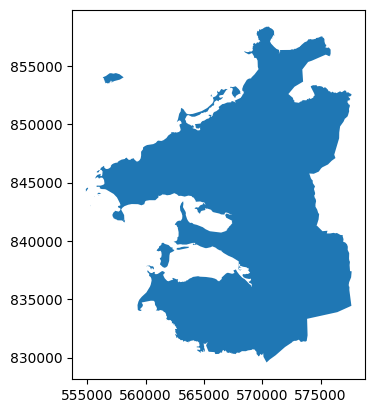

In [102]:
carbury = baronies_NW[baronies_NW['ENGLISH'] == 'CARBURY']
carbury.plot()

<Axes: >

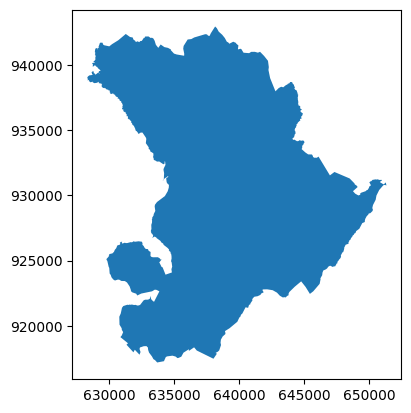

In [106]:
inishowen_west = baronies_NW[baronies_NW['ENGLISH'] == 'INISHOWEN WEST']
inishowen_west.plot()


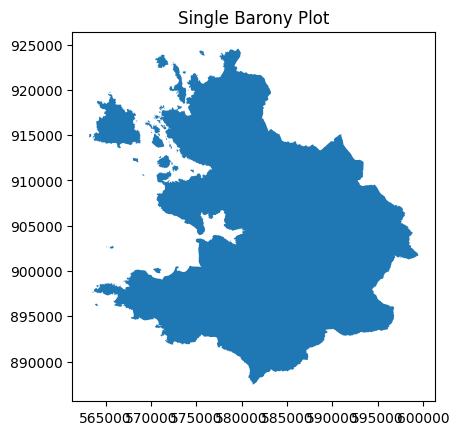

In [15]:
single_barony = baronies_NW.geometry[274]
# Create a GeoDataFrame with the single geometry
single_geometry_gdf = gpd.GeoDataFrame(geometry=[single_barony])

# Plot the single geometry
ax = single_geometry_gdf.plot()

# Add title to the plot
ax.set_title('Single Barony Plot')

# Show the plot
plt.show()






<Axes: >

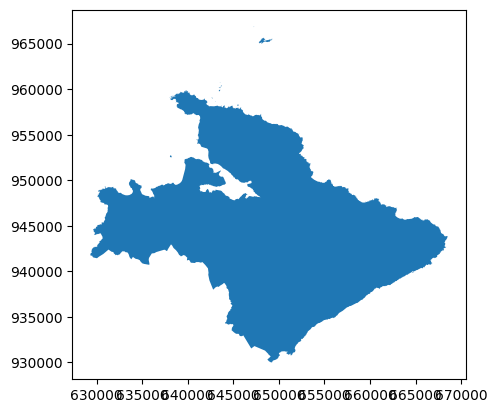

In [107]:
inishowen_east = baronies_NW[baronies_NW['ENGLISH'] == 'INISHOWEN EAST']
inishowen_east.plot()

REMOVE THE MONUMENT ENTRIES WITH UNKNOWN GEOMETRIES.

In [9]:
# Outliers are the sites whose locations are 0, 0. Remove them from the dataset and write them to a file for later. 

outlier = sites_nw[(sites_nw['ITM_E'].between(-1, 1)) & (sites_nw['ITM_N'].between(-1, 1))]
outlier


,OID_,OBJECTID,ENTITY_ID,CLASS_CODE,SMRS,COUNTY,TOWNLAND,COUNTY_ID,ZONE_ID,ITM_E,ITM_N,LATITUDE,LONGITUDE,MONUMENT_T,FIRST_EDIT,LATEST_EDI,WEBSITE_LI,WEB_NOTES,geometry
0,248,248,CV00251,UNCA,CV011-013009-,CAVAN,CORPORATION LANDS,3,R121602,0,0,46.488181,-15.817314,Castle - unclassified,NaN,NaN,https://maps.archaeology.ie/HistoricEnvironmen...,The Archaeological Survey of Ireland (ASI) is ...,POINT (0.000 0.000)
137,29404,29404,CV00044,CAIR,CV002-030001-,CAVAN,KILLYCARNEY,3,NaN,0,0,46.488181,-15.817314,Cairn - unclassified,NaN,Not indicated,https://maps.archaeology.ie/HistoricEnvironmen...,"Recorded by Wakeman (1879, 183-200) as a circu...",POINT (0.000 0.000)
138,29406,29406,CV00046,CAIR,CV002-031001-,CAVAN,TUAM,3,NaN,0,0,46.488181,-15.817314,Cairn - unclassified,NaN,Not indicated,https://maps.archaeology.ie/HistoricEnvironmen...,Not marked on any OS ed. Recorded by Wakeman (...,POINT (0.000 0.000)
271,29611,29611,CV00227,CRAN,CV010-024----,CAVAN,CRANAGHAN,3,NaN,0,0,46.488181,-15.817314,Crannog,NaN,Not indicated,https://maps.archaeology.ie/HistoricEnvironmen...,"Not marked on any OS ed. Mitchell (1941, 30) f...",POINT (0.000 0.000)
272,29612,29612,CV00228,CRAN,CV010-025----,CAVAN,TOMKINROAD,3,NaN,0,0,46.488181,-15.817314,Crannog,NaN,Not indicated,https://maps.archaeology.ie/HistoricEnvironmen...,Not marked on any OS ed. Davies (NMI Survey 19...,POINT (0.000 0.000)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9762,154883,154883,DG03911,BATT,DG045-038----,DONEGAL,KILMACRENAN (Kilmacrenan ED),7,NaN,0,0,46.488181,-15.817314,Battlefield,NaN,NaN,https://maps.archaeology.ie/HistoricEnvironmen...,The Archaeological Survey of Ireland (ASI) is ...,POINT (0.000 0.000)
9763,154900,154900,LE02616,BATT,LE000-001----,LEITRIM,Unknown,16,NaN,0,0,46.488181,-15.817314,Battlefield,NaN,NaN,https://maps.archaeology.ie/HistoricEnvironmen...,The Archaeological Survey of Ireland (ASI) is ...,POINT (0.000 0.000)
9764,154911,154911,LE02617,BATT,LE000-002----,LEITRIM,Unknown,16,NaN,0,0,46.488181,-15.817314,Battlefield,NaN,NaN,https://maps.archaeology.ie/HistoricEnvironmen...,The Archaeological Survey of Ireland (ASI) is ...,POINT (0.000 0.000)
9765,154932,154932,SL07408,BATT,SL000-001----,SLIGO,Unknown,25,NaN,0,0,46.488181,-15.817314,Battlefield,NaN,NaN,https://maps.archaeology.ie/HistoricEnvironmen...,The Archaeological Survey of Ireland (ASI) is ...,POINT (0.000 0.000)


In [10]:
outlier.info


<bound method DataFrame.info of         OID_  OBJECTID ENTITY_ID CLASS_CODE           SMRS   COUNTY  \
0        248       248   CV00251       UNCA  CV011-013009-    CAVAN   
137    29404     29404   CV00044       CAIR  CV002-030001-    CAVAN   
138    29406     29406   CV00046       CAIR  CV002-031001-    CAVAN   
271    29611     29611   CV00227       CRAN  CV010-024----    CAVAN   
272    29612     29612   CV00228       CRAN  CV010-025----    CAVAN   
...      ...       ...       ...        ...            ...      ...   
9762  154883    154883   DG03911       BATT  DG045-038----  DONEGAL   
9763  154900    154900   LE02616       BATT  LE000-001----  LEITRIM   
9764  154911    154911   LE02617       BATT  LE000-002----  LEITRIM   
9765  154932    154932   SL07408       BATT  SL000-001----    SLIGO   
9805  158809    158809   CV02553       RATH  CV017-078----    CAVAN   

                          TOWNLAND  COUNTY_ID  ZONE_ID  ITM_E  ITM_N  \
0                CORPORATION LANDS         

In [12]:
# The number of unique entries with no location is 357.

outlier.nunique()


OID_          357
OBJECTID      357
ENTITY_ID     357
CLASS_CODE     35
SMRS          357
COUNTY          4
TOWNLAND      267
COUNTY_ID       4
ZONE_ID         3
ITM_E           1
ITM_N           1
LATITUDE        1
LONGITUDE       1
MONUMENT_T     35
FIRST_EDIT      5
LATEST_EDI      5
WEBSITE_LI    357
WEB_NOTES     266
geometry        1
dtype: int64

In [13]:
#print to a text file 
with open('outlier.txt', 'w') as f:
    f.write(outlier.to_string())

In [16]:
# investigate a single entry in outliers to see if it is a valid entry.

outlier.iloc[5]

OID_                                                      29613
OBJECTID                                                  29613
ENTITY_ID                                               CV00229
CLASS_CODE                                                 CHUR
SMRS                                              CV010-026----
COUNTY                                                    CAVAN
TOWNLAND                                                AUGHRIM
COUNTY_ID                                                     3
ZONE_ID                                                     NaN
ITM_E                                                         0
ITM_N                                                         0
LATITUDE                                              46.488181
LONGITUDE                                            -15.817314
MONUMENT_T                                               Church
FIRST_EDIT                                                  NaN
LATEST_EDI                              

In [17]:
sites_nw.columns

Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'geometry'],
      dtype='object')

In [18]:
# Get the indices of the outliers
outlier_indices = outlier.index

# Drop the outliers from the original DataFrame
sites_nw_clean = sites_nw.drop(outlier_indices)

# sites_nw_clean is the original DataFrame without the outliers
# And outlier is a separate GeoDataFrame containing only the outliers

In [19]:
# Write the cleaned DataFrame to a shapefile

sites_nw_clean
sites_nw_clean.to_file('/Users/mensab/Documents/GISMapFiles/Files1600/sites_nw_clean.shp')

# Write the outliers to a shapefile
outlier
outlier.to_file('/Users/mensab/Documents/GISMapFiles/Files1600/outlierMonuments.shp')

NameError: name 'baronies_NW' is not defined

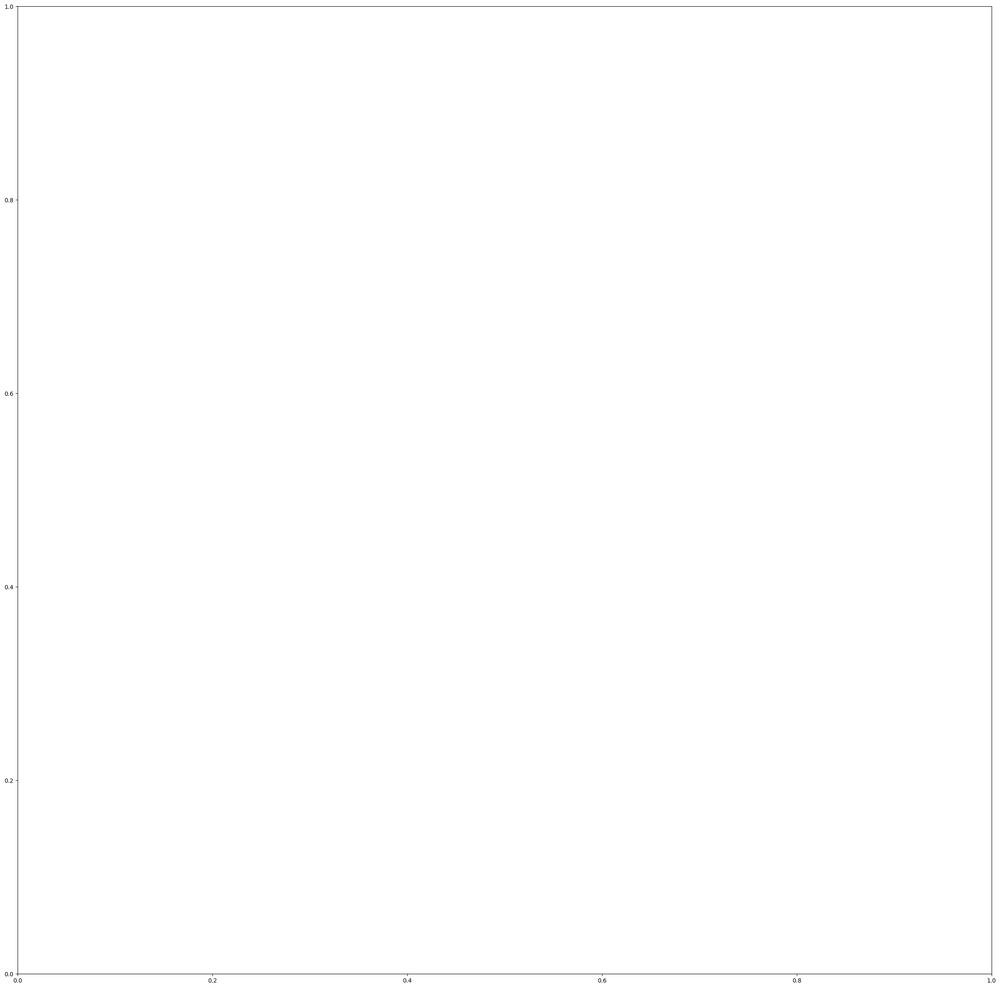

In [20]:
#baronies_NW.plot(column='AREA', legend=True)
#baronies_NW.boundary.plot()

# Plot the baronies and the sites together

fig, ax = plt.subplots(figsize=(30, 30))

baronies_NW.plot(ax=ax,column = 'AREA', cmap = 'Greys_r', facecolor='gray', edgecolor='black', zorder=1,)

sites_nw_clean.plot(ax=ax, column='MONUMENT_T', legend=True,legend_kwds={'title': "MON_T", 'loc': 'upper left', 'bbox_to_anchor': (1, 1)}, markersize=4, zorder=2)

#Annotate each polygon with its 'ENGLISH' name
for x, y, label in zip(baronies_NW.centroid.x, baronies_NW.centroid.y, baronies_NW['ENGLISH']):
    ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords='offset points', fontsize=8)







In [ ]:
from shapely.ops import unary_union

Inis_Eoghan = (unary_union[inishowen_east['geometry'],inishowen_west['geometry']])

TypeError: 'method' object is not subscriptable

In [ ]:
# FAILED ATTEMPTS TO CREATE TERRITORIES

#merge_barony = baronies_NW.dissolve(by='COUNTY')

In [27]:
baronies_NW.info


<bound method DataFrame.info of       BY_ID         ENGLISH              GAEILGE LOGAINM_ID        CONTAE  \
8     29004  LOUGHTEE LOWER  Lucht Tí Íochtarach         13     An Cabhán   
12    59008         TIRHUGH            Tír Aodha         52  Dún na nGall   
14    29006        TULLYHAW     Teallach Eathach         14     An Cabhán   
28    29005     TULLYGARVEY  Teallach Ghairbhíth         16     An Cabhán   
42   119002      DRUMAHAIRE      Droim Dhá Thiar        137      Liatroim   
83    29001     CASTLERAHAN     Caisleán Raithin         10     An Cabhán   
94    59005     KILMACRENAN    Cill Mhic Réanáin         55  Dún na nGall   
129  209003          CORRAN            An Corann        229      Sligeach   
134   29003       CLANMAHON       Clann Mhathúna          9     An Cabhán   
141   59001          BANAGH              Báinigh         54  Dún na nGall   
142  209002        COOLAVIN        Cúil Ó bhFinn        228      Sligeach   
144  119003         LEITRIM             Liat

Rivers and Lakes data

In [28]:
rivers_lakes = gpd.read_file("/Users/mensab/Documents/GISMapFiles/Rivers&Lakes/Shapefiles")
rivers_lakes

,OBJECTID,SEG_CD,NAME,AREA_,HECTARE,PERIMETER,HYDRO_AR,ORDER_,OS_LAYER,SOURCE,LWB,EDENLakeCo,Shape_STAr,Shape_STLe,geometry
0,1,34_1,NaN,0.002,0.174650,148.152773,34,-99.0,reservoir,epa,N,NaN,1.746498e+03,148.152773,"POLYGON ((113947.176 292650.532, 113947.176 29..."
1,2,34_2,NaN,0.002,0.168753,145.631645,34,-99.0,reservoir,epa,N,NaN,1.687534e+03,145.631645,"POLYGON ((113891.838 292649.223, 113891.838 29..."
2,3,34_3,NaN,0.000,0.045238,75.408867,34,-99.0,reservoir,epa,N,NaN,4.523752e+02,75.408867,"POLYGON ((119811.159 319583.855, 119811.151 31..."
3,4,34_4,NaN,0.001,0.060457,102.438843,34,-99.0,pond,epa,N,NaN,6.045697e+02,102.438843,"POLYGON ((148454.106 281486.625, 148454.362 28..."
4,5,34_5,NaN,0.003,0.259570,206.013992,34,-99.0,pond,epa,N,NaN,2.595699e+03,206.013992,"POLYGON ((141211.791 283056.662, 141213.903 28..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12212,9192,32_509a,Pollacappul Lough,0.254,25.509374,3827.503729,32,5.0,NaN,epa,Y,32001330040,2.550937e+05,3827.503729,"POLYGON ((75473.267 258248.239, 75485.251 2582..."
12213,9193,32_509b,Kylemore Lough,1.335,134.091553,6016.860382,32,5.0,NaN,epa,Y,32001330050,1.340916e+06,6016.860382,"POLYGON ((76100.587 258107.143, 76090.524 2581..."
12214,9194,26_747c,Tap (Lough),0.112,11.254331,2149.103677,26,6.0,LAKE,epa,Y,260155a1815,1.125433e+05,2149.103677,"POLYGON ((200673.808 294130.860, 200881.064 29..."
12215,937,32_402,Beaghcauneen Lough,0.184,18.520070,3378.220801,32,3.0,NaN,epa,Y,32t4_320270,1.852007e+05,3378.220801,"POLYGON ((68219.412 246975.360, 68208.640 2469..."


In [29]:
rivers_lakes.info

<bound method DataFrame.info of        OBJECTID   SEG_CD                NAME  AREA_     HECTARE    PERIMETER  \
0             1     34_1                 NaN  0.002    0.174650   148.152773   
1             2     34_2                 NaN  0.002    0.168753   145.631645   
2             3     34_3                 NaN  0.000    0.045238    75.408867   
3             4     34_4                 NaN  0.001    0.060457   102.438843   
4             5     34_5                 NaN  0.003    0.259570   206.013992   
...         ...      ...                 ...    ...         ...          ...   
12212      9192  32_509a   Pollacappul Lough  0.254   25.509374  3827.503729   
12213      9193  32_509b      Kylemore Lough  1.335  134.091553  6016.860382   
12214      9194  26_747c         Tap (Lough)  0.112   11.254331  2149.103677   
12215       937   32_402  Beaghcauneen Lough  0.184   18.520070  3378.220801   
12216       938   32_403    Connor ( Lough )  0.002    0.166810   160.635907   

      H

In [30]:
rivers_lakes.columns
rivers_lakes.crs

<Projected CRS: EPSG:29902>
Name: TM65 / Irish Grid
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Ireland - onshore.
- bounds: (-10.56, 51.39, -5.93, 55.43)
Coordinate Operation:
- name: Irish Grid
- method: Transverse Mercator
Datum: TM65
- Ellipsoid: Airy Modified 1849
- Prime Meridian: Greenwich

<Axes: title={'center': 'Rivers and Lakes'}>

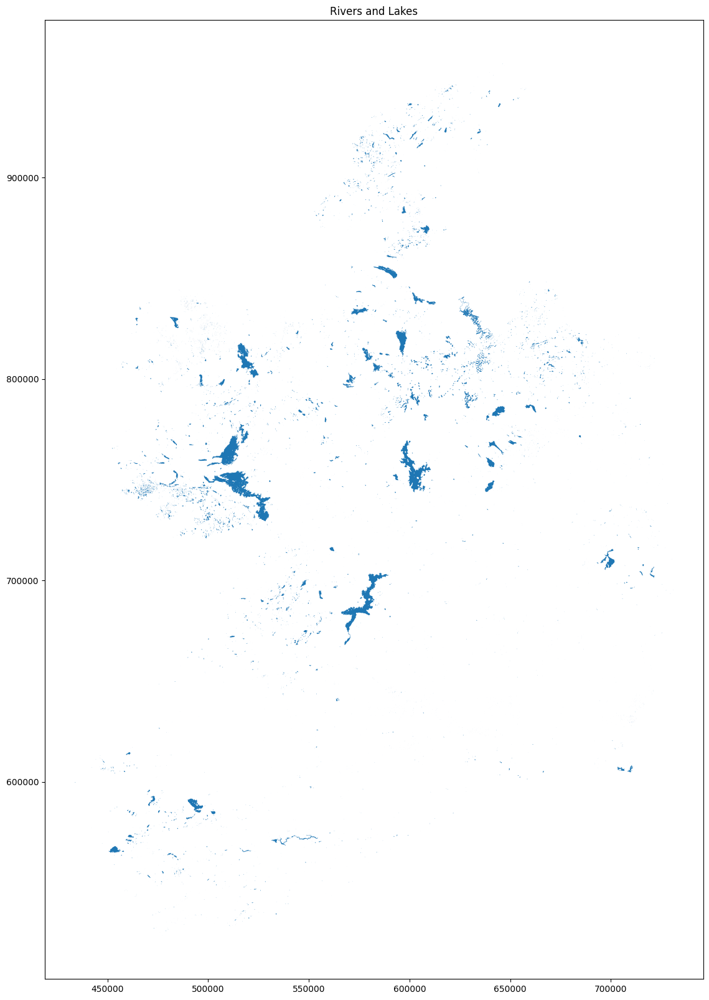

In [31]:
rivers_lakes.to_crs(epsg=2157, inplace=True)

fig, ax = plt.subplots(figsize=(20, 20))
ax.set_title('Rivers and Lakes')
rivers_lakes.plot(ax=ax)


In [32]:
rivers_lakes.crs

<Projected CRS: EPSG:2157>
Name: IRENET95 / Irish Transverse Mercator
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Ireland - onshore. United Kingdom (UK) - Northern Ireland (Ulster) - onshore.
- bounds: (-10.56, 51.39, -5.34, 55.43)
Coordinate Operation:
- name: Irish Transverse Mercator
- method: Transverse Mercator
Datum: IRENET95
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

INTERSECTION OPERATIONS TO SELECT THE RIVERS AND LAKES IN THE COUNTIES OF INTEREST. ALSO THE SOILS MAPS AND HEIGHT MAPS IF POSSIBLE. 

In [33]:
# Assuming gdf1 and gdf2 are your GeoDataFrames
# First set the CRS to be the same for both GeoDataFrames

baronies_NW = baronies_NW.reset_index(drop=True)
rivers_lakes = rivers_lakes.reset_index(drop=True)

# Now you can perform the intersection
rivers_lakes_nw = gpd.overlay(baronies_NW, rivers_lakes, how='intersection')


#rivers_lakes_nw = rivers_lakes.intersection(baronies_NW)
#rivers_lakes_nw.plot()


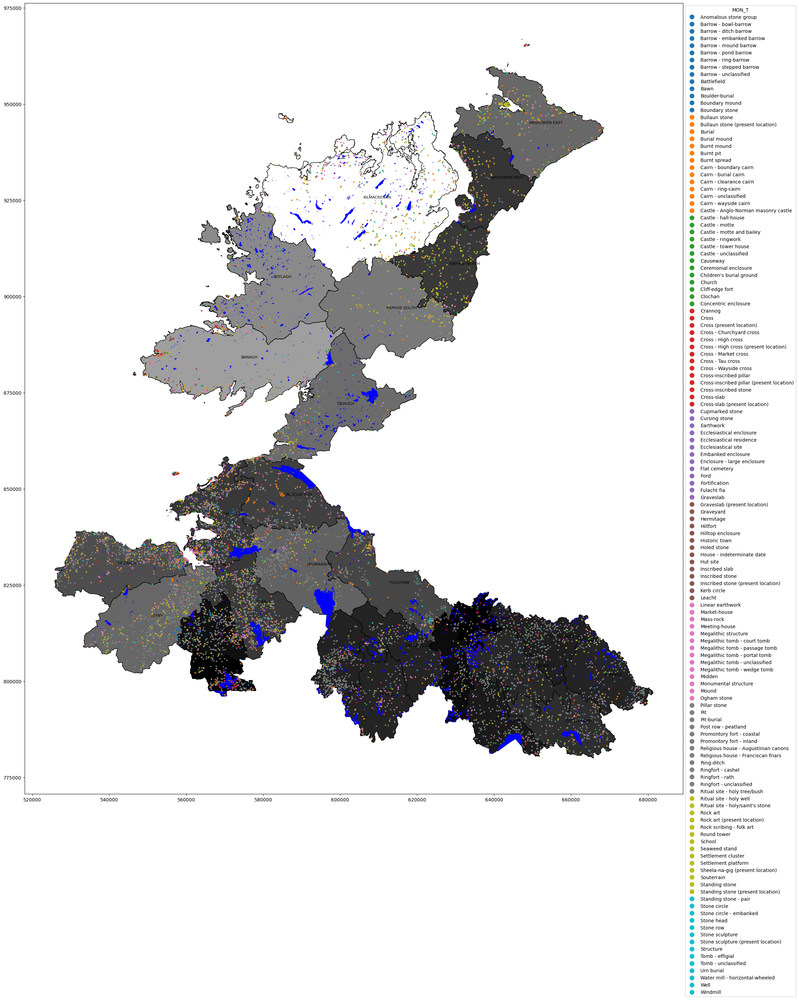

In [34]:
# Plot the baronies and the sites together

fig, ax = plt.subplots(figsize=(30, 30))

baronies_NW.plot(ax=ax,column = 'AREA', cmap = 'Greys_r', facecolor='gray', edgecolor='black', zorder=1,)

sites_nw_clean.plot(ax=ax, column='MONUMENT_T', legend=True,legend_kwds={'title': "MON_T", 'loc': 'upper left', 'bbox_to_anchor': (1, 1)}, markersize=4, zorder=2)

rivers_lakes_nw.plot(ax=ax, color='blue', zorder=3)

#Annotate each polygon with its 'ENGLISH' name
for x, y, label in zip(baronies_NW.centroid.x, baronies_NW.centroid.y, baronies_NW['ENGLISH']):
    ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords='offset points', fontsize=8)

In [35]:
# Save rivers and lakes to a shapefile
rivers_lakes_nw.to_file('/Users/mensab/Documents/GISMapFiles/Files1600/rivers_lakes_nw.shp')


In [36]:
rivers = gpd.read_file("/Users/mensab/Documents/GISMapFiles/Files1600/Wastewater_Treatment_and_Disposal")



In [37]:

rivers.columns
#rivers.crs

Index(['EPA_NAME', 'Last_Updat', 'Policy01_N', 'Owning_Org', 'Metadata_L',
       'Map_Featur', 'OBJECTID', 'Shape__Len', 'geometry'],
      dtype='object')

In [38]:
rivers.info


<bound method DataFrame.info of                          EPA_NAME  Last_Updat  \
0                             NaN        2020   
1                             NaN        2020   
2                             NaN        2020   
3                             NaN        2020   
4                       KINLETTER        2020   
...                           ...         ...   
102103                        NaN        2020   
102104                        NaN        2020   
102105                        NaN        2020   
102106  Cor Trib, Annareagh South        2020   
102107                        NaN        2020   

                                        Policy01_N Owning_Org  \
0       Wastewater Treatment and Disposal Policy 2        EPA   
1       Wastewater Treatment and Disposal Policy 2        EPA   
2       Wastewater Treatment and Disposal Policy 2        EPA   
3       Wastewater Treatment and Disposal Policy 2        EPA   
4       Wastewater Treatment and Disposal Policy 2    

In [39]:
rivers.to_crs(epsg=2157, inplace=True)

rivers = rivers_lakes.reset_index(drop=True)

# Now you can perform the intersection
rivers_nw = gpd.overlay(baronies_NW, rivers, how='intersection')



<Axes: >

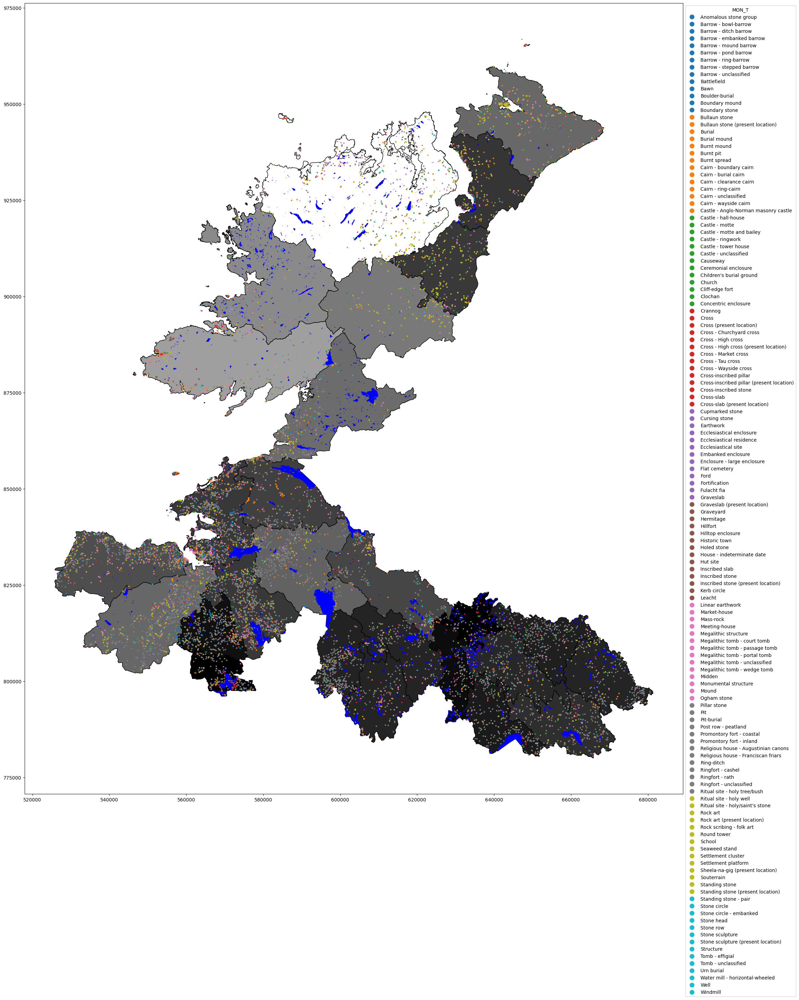

In [40]:
fig, ax = plt.subplots(figsize=(30, 30))
baronies_NW.plot(ax=ax,column = 'AREA', cmap = 'Greys_r', facecolor='gray', edgecolor='black', zorder=1,)
sites_nw_clean.plot(ax=ax, column='MONUMENT_T', legend=True,legend_kwds={'title': "MON_T", 'loc': 'upper left', 'bbox_to_anchor': (1, 1)}, markersize=4, zorder=2)
rivers_nw.plot(ax=ax, color='blue', zorder=3)



In [41]:
# Save rivers_nw to a shapefile
rivers_nw.to_file('/Users/mensab/Documents/GISMapFiles/Files1600/rivers_nw.shp')



In [42]:
soils_map = gpd.read_file("/Users/mensab/Documents/GISMapFiles/SOIL_SISNationalSoils_shp/Data/SOIL_SISNationalSoils_Shp")
soils_map

,OBJECTID,Associatio,Associat_1,Associat_2,Texture_Su,ha,URL,UniqueID,DRAINAGE,TEXTURE,DEPTH,SHAPE_Leng,SHAPE_Area,SOC,geometry
0,1,1xx,01_Bk,Peat,Peat,8.936193,http://gis.teagasc.ie/soils/,1,Poor,Peat,NaN,1612.721788,8.936193e+04,0.000000,"POLYGON ((74141.240 25254.740, 74092.700 25245..."
1,2,1xx,01_Bk,Peat,Peat,43.004953,http://gis.teagasc.ie/soils/,2,Poor,Peat,NaN,4174.929755,4.300495e+05,0.000000,"POLYGON ((78486.370 30618.920, 78508.940 30610..."
2,3,1xx,01_Bk,Peat,Peat,7.128532,http://gis.teagasc.ie/soils/,3,Poor,Peat,NaN,2277.477286,7.128532e+04,0.000000,"POLYGON ((84084.850 31526.640, 84063.110 31491..."
3,4,1xx,01_Bk,Peat,Peat,7.197259,http://gis.teagasc.ie/soils/,4,Poor,Peat,NaN,1196.079972,7.197259e+04,0.000000,"POLYGON ((91463.380 32014.920, 91460.570 31969..."
4,5,1xx,01_Bk,Peat,Peat,6.084085,http://gis.teagasc.ie/soils/,5,Poor,Peat,NaN,2059.571505,6.084085e+04,0.000000,"POLYGON ((120492.310 32806.090, 120498.080 327..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25138,25139,1100n,1100n,Clashmore,Coarse loamy drift with siliceous stones,848.713170,http://gis.teagasc.ie/soils/,25139,Well,Coarse loamy,>80,9684.906739,2.557408e+06,128.266457,"POLYGON ((67045.300 110520.900, 66988.690 1105..."
25139,25140,0xx,0xx,Blown sand/Dune,Blown sand/Dune,848.713170,http://gis.teagasc.ie/soils/,25140,Other,NaN,NaN,5076.834387,1.722818e+05,0.000000,"POLYGON ((68869.436 110728.769, 68824.262 1107..."
25140,25141,0xx,0xx,Blown sand/Dune,Blown sand/Dune,975.912286,http://gis.teagasc.ie/soils/,25141,Other,NaN,NaN,7006.112925,5.182461e+05,0.000000,"POLYGON ((74033.470 112014.260, 74014.286 1120..."
25141,25142,1030a,1030a,Crosstown,Fine loamy drift with siliceous stones,466.722101,http://gis.teagasc.ie/soils/,25142,imperfectly,Fine loamy,40-80,7890.186816,1.768115e+06,121.136359,"POLYGON ((72098.729 116655.682, 71913.669 1166..."


In [43]:
soils_map.crs

<Projected CRS: EPSG:29902>
Name: TM65 / Irish Grid
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Ireland - onshore.
- bounds: (-10.56, 51.39, -5.93, 55.43)
Coordinate Operation:
- name: Irish Grid
- method: Transverse Mercator
Datum: TM65
- Ellipsoid: Airy Modified 1849
- Prime Meridian: Greenwich

SOILS


In [44]:
soils_map.columns

Index(['OBJECTID', 'Associatio', 'Associat_1', 'Associat_2', 'Texture_Su',
       'ha', 'URL', 'UniqueID', 'DRAINAGE', 'TEXTURE', 'DEPTH', 'SHAPE_Leng',
       'SHAPE_Area', 'SOC', 'geometry'],
      dtype='object')

In [45]:
soils_map.info


<bound method DataFrame.info of        OBJECTID Associatio Associat_1       Associat_2  \
0             1        1xx      01_Bk             Peat   
1             2        1xx      01_Bk             Peat   
2             3        1xx      01_Bk             Peat   
3             4        1xx      01_Bk             Peat   
4             5        1xx      01_Bk             Peat   
...         ...        ...        ...              ...   
25138     25139      1100n      1100n        Clashmore   
25139     25140        0xx        0xx  Blown sand/Dune   
25140     25141        0xx        0xx  Blown sand/Dune   
25141     25142      1030a      1030a        Crosstown   
25142     25143        0xx        0xx  Blown sand/Dune   

                                     Texture_Su          ha  \
0                                          Peat    8.936193   
1                                          Peat   43.004953   
2                                          Peat    7.128532   
3                  

In [47]:
soils_map.to_crs(epsg=2157, inplace=True)

soils_map = soils_map.reset_index(drop=True)

# Now you can perform the intersection
soils_map_nw = gpd.overlay(baronies_NW, soils_map, how='intersection')



In [55]:
# Extract unique values from Drainage column
soils_map_nw['DRAINAGE'].unique()





array(['Poor', 'imperfectly', 'Well', 'Other', 'moderately', nan],
      dtype=object)

/var/folders/lk/44yhnrk92p95sjc8gdd7165h0000gn/T/ipykernel_4387/4160430196.py:5: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  sites_nw_clean.plot(ax=ax,color = 'black', column='MONUMENT_T', markersize=4, zorder=3)


<Axes: title={'center': 'Soils'}>

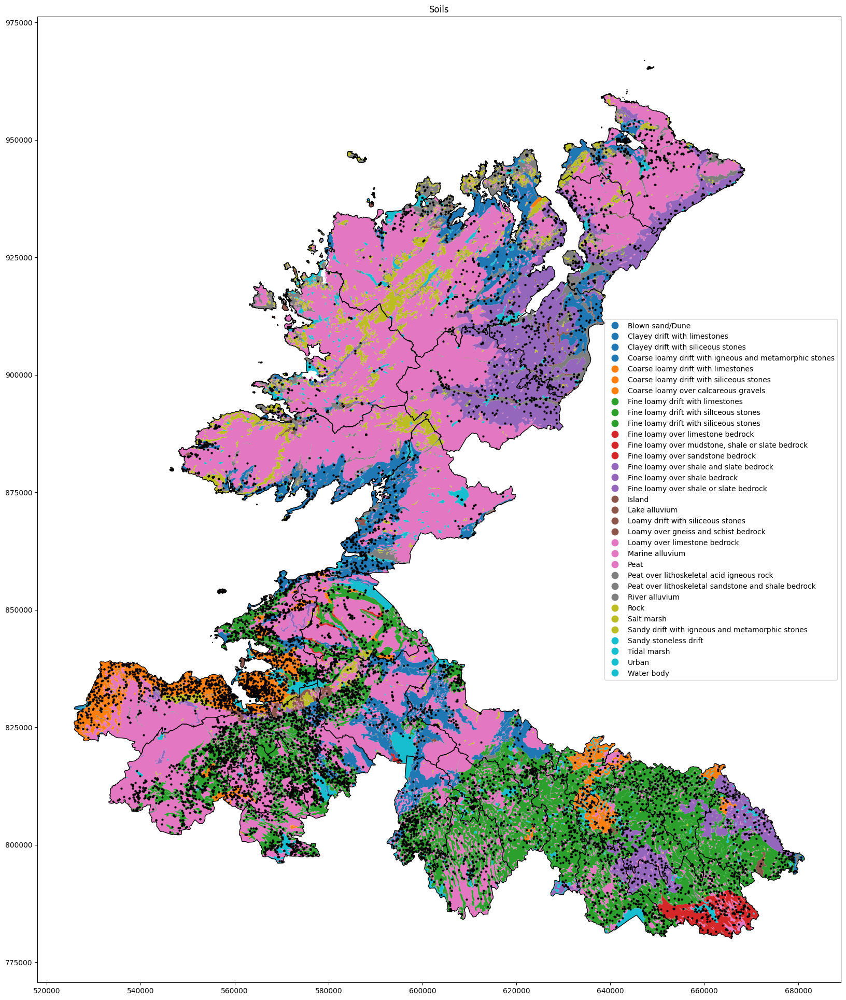

In [48]:

fig, ax = plt.subplots(figsize=(20, 30))
ax.set_title('Soils')
baronies_NW.plot(ax=ax, color='none', edgecolor='black', zorder=2)

sites_nw_clean.plot(ax=ax,color = 'black', column='MONUMENT_T', markersize=4, zorder=3)

soils_map_nw.plot(ax=ax,column='Texture_Su', legend=True, zorder=1) 


In [49]:
# number of unique values in the column
soils_map_nw['Texture_Su'].nunique()


33

In [56]:
# Save soils_map_nw to a shapefile
soils_map_nw.to_file('/Users/mensab/Documents/GISMapFiles/Files1600/soils_map_nw.shp')


In [ ]:
# Merge Inishowen East and West
merged_inishowen = gpd.GeoDataFrame(pd.concat([inishowen_east, inishowen_west], ignore_index=True), crs=inishowen_east.crs)


In [57]:
tii_data = gpd.read_file("zip:////Users/mensab/Documents/GISMapFiles/TIIArchaeology.zip")
tii_data

,dc_identif,url,Townland,dc_title,dc_publish,dc_creator,dc_creat_1,dc_creat_2,dc_creat_3,dc_subject,dc_subje_1,dc_subje_2,dc_subje_3,dc_subje_4,dc_contrib,ITM_X,ITM_Y,Latitude,Longitude,geometry
0,00E0810,https://repository.dri.ie/catalog/0000cd770,Sheephouse,"Archaeological excavation report, 00E0810 Shee...",Transport Infrastructure Ireland,"Moore, Declan",NaN,NaN,NaN,Ring-ditch,Kiln - corn-drying,Habitation site,Field system,NaN,Irish Archaeological Consultancy Ltd.,705948.11,774647.57,53.710747,-6.395089,POINT (705948.110 774647.570)
1,03E0158,https://repository.dri.ie/catalog/0000cd788,Balregan,"Archaeological excavation report, 03E0158 Site...",Transport Infrastructure Ireland,"Delaney, Shane",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Irish Archaeological Consultancy Ltd.,702735.13,810103.95,54.029886,-6.431870,POINT (702735.130 810103.950)
2,E3047,https://repository.dri.ie/catalog/0000cd79j,Leshamstown,"Archaeological excavation report, E3047 Lesha...",Transport Infrastructure Ireland,"Schweitzer, Holger","Ginn, Vicky",NaN,NaN,Pit,Burnt mound,NaN,NaN,NaN,Archaeological Consultancy Services Ltd,695320.17,751836.57,53.507868,-6.562996,POINT (695320.170 751836.570)
3,E3187,https://repository.dri.ie/catalog/0000cd809,Derver,"Archaeological excavation report, E3187 Derve...",Transport Infrastructure Ireland,"Reilly, Stuart","Ginn, Vicky",NaN,NaN,Pit,Hearth,NaN,NaN,NaN,Archaeological Consultancy Services Ltd,666275.63,780427.55,53.769222,-6.994678,POINT (666275.630 780427.550)
4,02E1145,https://repository.dri.ie/catalog/0000cd81k,Towlaght,"Archaeological excavation report, 02E1145 Tow...",Transport Infrastructure Ireland,"Linnane, Stephen",NaN,NaN,NaN,Fulacht fia,Pit,NaN,NaN,NaN,Archaeological Consultancy Services Ltd.,664552.74,743658.51,53.460778,-7.132455,POINT (664552.740 743658.510)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1625,02E1144,https://repository.dri.ie/catalog/zs269q242,Griffinstown,"Archaeological excavation report, 02E1144 Gri...",Transport Infrastructure Ireland,"Linnane, Stephen",NaN,NaN,NaN,Metalworking site,Kiln,NaN,NaN,NaN,Archaeological Consultancy Services Ltd.,657611.26,745986.05,53.460778,-7.132455,POINT (657611.260 745986.050)
1626,E2440,https://repository.dri.ie/catalog/zs269q25b,Ballykeeran,"Archaeological excavation report, E2440 Bally...",Transport Infrastructure Ireland,"Wilkins, Brendon",NaN,NaN,NaN,Cist,Ring-ditch,Cremated remains,Cremated remains,NaN,Headland Archaeology Ltd,560379.29,722806.53,53.254138,-8.593745,POINT (560379.290 722806.530)
1627,E3874,https://repository.dri.ie/catalog/zs269q26m,Ballynaclogh,"Archaeological excavation report, E3874 Bally...",Transport Infrastructure Ireland,"Maginness, Clare","O'Dowd, Jean",NaN,NaN,Prehistoric site - lithic scatter,Settlement platform,Structure - peatland,Road - class 3 togher,NaN,The Archaeology Company,574088.33,726504.66,53.288218,-8.388612,POINT (574088.330 726504.660)
1628,03E1458,https://repository.dri.ie/catalog/zs269q331,Ballynamona,"Archaeological excavation report, 03E1458 Bal...",Transport Infrastructure Ireland,"Cotter, Eamonn",NaN,NaN,NaN,Pit,NaN,NaN,NaN,NaN,Archaeological Consultancy Services Ltd,581781.34,599792.07,52.149672,-8.266217,POINT (581781.340 599792.070)


In [58]:
tii_data.crs


<Projected CRS: EPSG:2157>
Name: IRENET95 / Irish Transverse Mercator
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Ireland - onshore. United Kingdom (UK) - Northern Ireland (Ulster) - onshore.
- bounds: (-10.56, 51.39, -5.34, 55.43)
Coordinate Operation:
- name: Irish Transverse Mercator
- method: Transverse Mercator
Datum: IRENET95
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [73]:
tii_data.columns


Index(['dc_identif', 'url', 'Townland', 'dc_subject', 'dc_subje_1',
       'dc_subje_2', 'dc_subje_3', 'dc_subje_4', 'ITM_X', 'ITM_Y', 'Latitude',
       'Longitude', 'geometry'],
      dtype='object')

In [72]:
# Drop the columns that are not needed
tii_data.drop(['dc_title', 'dc_publish', 'dc_creator', 'dc_creat_1', 'dc_creat_2', 'dc_creat_3', 'dc_contrib'], axis=1, inplace=True)  


KeyError: "['dc_title', 'dc_publish', 'dc_creator', 'dc_creat_1', 'dc_creat_2', 'dc_creat_3', 'dc_contrib'] not found in axis"

In [74]:
tii_data.columns

Index(['dc_identif', 'url', 'Townland', 'dc_subject', 'dc_subje_1',
       'dc_subje_2', 'dc_subje_3', 'dc_subje_4', 'ITM_X', 'ITM_Y', 'Latitude',
       'Longitude', 'geometry'],
      dtype='object')

<Axes: title={'center': 'TII Data'}>

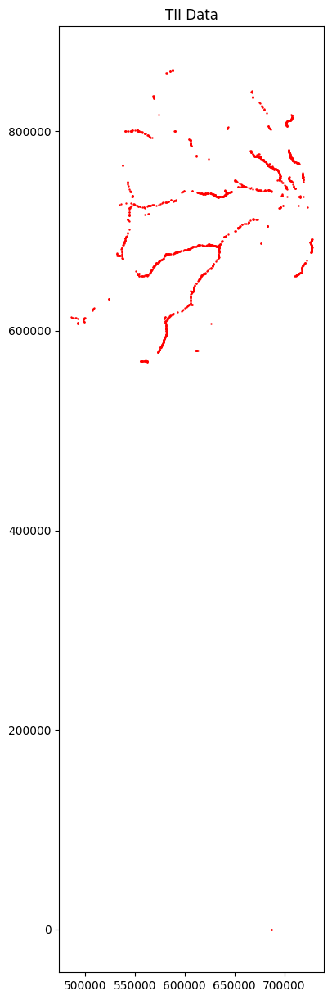

In [78]:
# Plot the tii data
fig, ax = plt.subplots(figsize=(15, 15))
ax.set_title('TII Data')
tii_data.plot(ax=ax, color='red', markersize=0.5, zorder=2)
# baronies_NW.plot(ax=ax, color='none', edgecolor='black', zorder=1)

# THIS DATA IS NOT SUITABLE FOR SPATIAL ANALYSIS 

In [109]:
# Save baronies_NW to a shapefile
baronies_NW.to_file('/Users/mensab/Documents/GISMapFiles/Files1600/baronies_NW.shp')


In [110]:
baronies_NW.index

Index([  8,  12,  14,  28,  42,  83,  94, 129, 134, 141, 142, 144, 156, 161,
       164, 173, 175, 193, 199, 204, 237, 238, 240, 255, 274, 277, 279],
      dtype='int64')

In [128]:
# Merge Inishowen East and West attempt 34, 35m 36, 37, 38 !!!!!!!!!

from shapely.ops import unary_union

# Filter the rows for 'Inishowen East' and 'Inishowen West'
#inishowen_east = baronies_NW[baronies_NW['ENGLISH'] == 'INISHOWEN EAST']
#inishowen_west = baronies_NW[baronies_NW['ENGLISH'] == 'INISHOWEN WEST']

# Use unary_union to merge the geometries
#inishowen_geometry = unary_union([inishowen_east.geometry.unary_union, inishowen_west.geometry.unary_union])

## Now inishowen_geometry is a single geometry that covers the area of both 'Inishowen East' and 'Inishowen West'

/var/folders/lk/44yhnrk92p95sjc8gdd7165h0000gn/T/ipykernel_4387/1139069421.py:10: FutureWarning: `unary_union` returned None due to all-None GeoSeries. In future, `unary_union` will return 'GEOMETRYCOLLECTION EMPTY' instead.
  inishowen_geometry = unary_union([inishowen_east.geometry.unary_union, inishowen_west.geometry.unary_union])


In [126]:
#new_row = inishowen_east.iloc[0].copy()  # Copy the first row of 'Inishowen East'

#new_row.geometry = inishowen_geometry  # Set the geometry to the new merged geometry

## Append the new row to the GeoDataFrame
#new_row_df = gpd.GeoDataFrame([new_row], columns=baronies_NW.columns) 
# Create a new GeoDataFrame from the new row , append is deprecated in pandas 1.0.0


baronies_NW = pd.concat([baronies_NW, new_row_df])  # Append the new row to the GeoDataFrame


# Drop the rows for 'Inishowen East' and 'Inishowen West'
baronies_NW = baronies_NW[~baronies_NW['ENGLISH'].isin(['INISHOWEN EAST', 'INISHOWEN WEST'])]


/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/geopandas/array.py:1459: UserWarning: CRS not set for some of the concatenation inputs. Setting output's CRS as IRENET95 / Irish Transverse Mercator (the single non-null crs provided).
  return GeometryArray(data, crs=_get_common_crs(to_concat))


In [130]:
inishowen_geometry


/var/folders/lk/44yhnrk92p95sjc8gdd7165h0000gn/T/ipykernel_4387/227545917.py:2: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  inishowen_east.plot(edgecolor='black', zorder=1)


<Axes: >

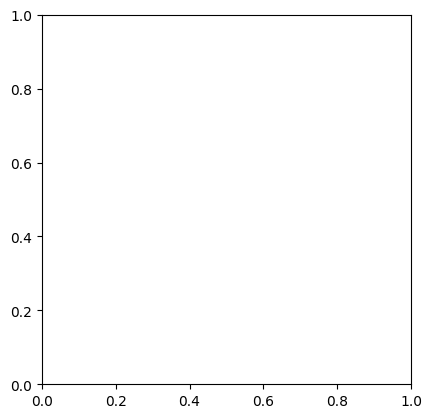

In [127]:
inishowen_east = baronies_NW[baronies_NW['ENGLISH'] == 'INISHOWEN WEST']
inishowen_east.plot(edgecolor='black', zorder=1)

<Axes: title={'center': 'Baronies'}>

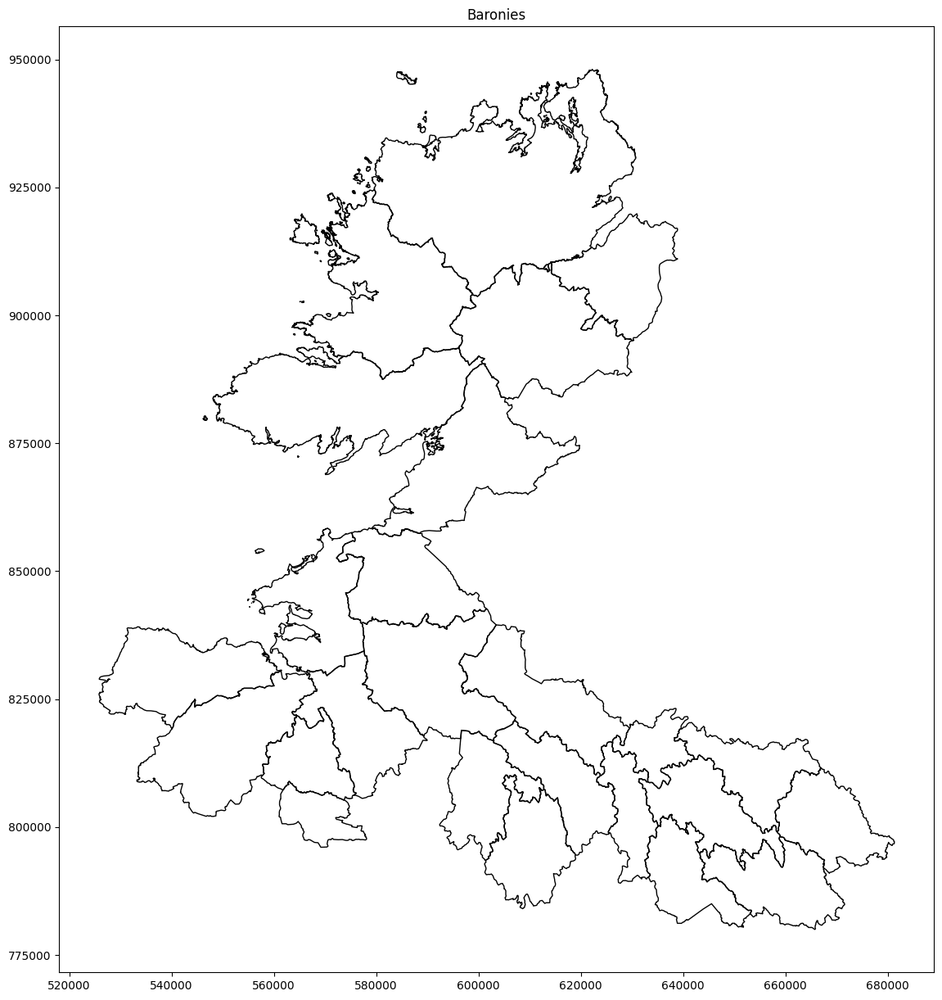

In [88]:
# plot baronies again
fig, ax = plt.subplots(figsize=(15, 15))
ax.set_title('Baronies')
baronies_NW.plot(ax=ax, color='none', edgecolor='black', zorder=1)


In [ ]:
# save the new file 
soils_map_nw.to_file('/Users/mensab/Documents/GISMapFiles/Files1600/soils_map_nw.shp')

# Extract the soil ot location of each ringfort and standing stone and every monumnent type
# 1. Create a new column in the sites_nw_clean dataframe
# 2. Use the spatial join function to extract the soil type for each monument
# 3. Save the new file as a shapefile


In [ ]:
# Mark the centroid of each barony and plot a buffer around it

# Plot a buffer around the border of each barony


In [103]:
#Directory containing your HGT files
hgt_directory = "/Users/mensab/Documents/GISMapFiles/Files1600/N29"

# Iterate over HGT files in the directory
for filename in os.listdir(hgt_directory):
    if filename.endswith(".hgt"):
        hgt_path = os.path.join(hgt_directory, filename)

        # Open the HGT file
        with rasterio.open(hgt_path, 'r') as src:
            # Read and print basic information
            print(f"File: {filename}")
            print(f"CRS: {src.crs}")
            print(f"Bounds: {src.bounds}")
            print(f"Resolution: {src.res}")
            print(f"Width x Height: {src.width} x {src.height}")
            print("\n")



File: N54W011.hgt
CRS: EPSG:4326
Bounds: BoundingBox(left=-11.00013888888889, bottom=53.999861111111116, right=-9.999861111111112, top=55.00013888888889)
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Width x Height: 3601 x 3601


File: N54W010.hgt
CRS: EPSG:4326
Bounds: BoundingBox(left=-10.00013888888889, bottom=53.999861111111116, right=-8.999861111111112, top=55.00013888888889)
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Width x Height: 3601 x 3601


File: N54W012.hgt
CRS: EPSG:4326
Bounds: BoundingBox(left=-12.00013888888889, bottom=53.999861111111116, right=-10.999861111111112, top=55.00013888888889)
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Width x Height: 3601 x 3601


File: N54W007.hgt
CRS: EPSG:4326
Bounds: BoundingBox(left=-7.0001388888888885, bottom=53.999861111111116, right=-5.999861111111111, top=55.00013888888889)
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Width x Height: 3601 x 3601


File: N55W012.hgt
CRS: EPS

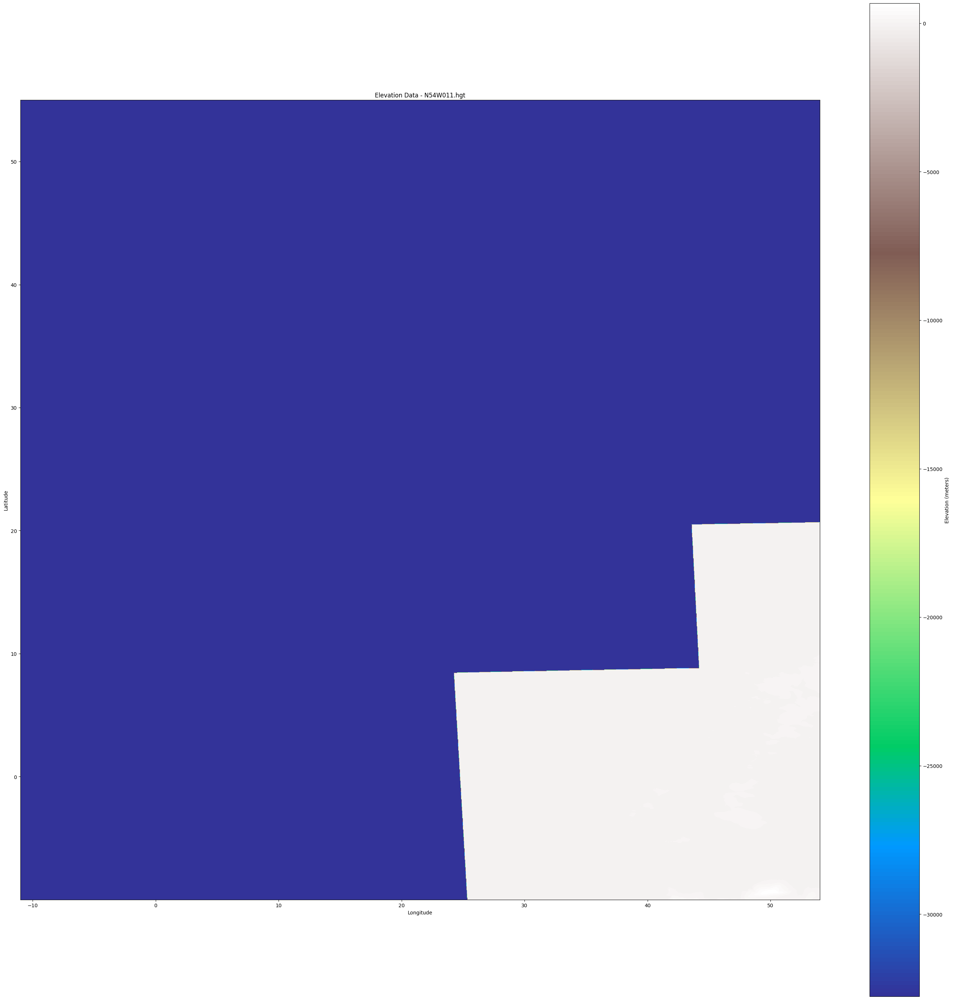

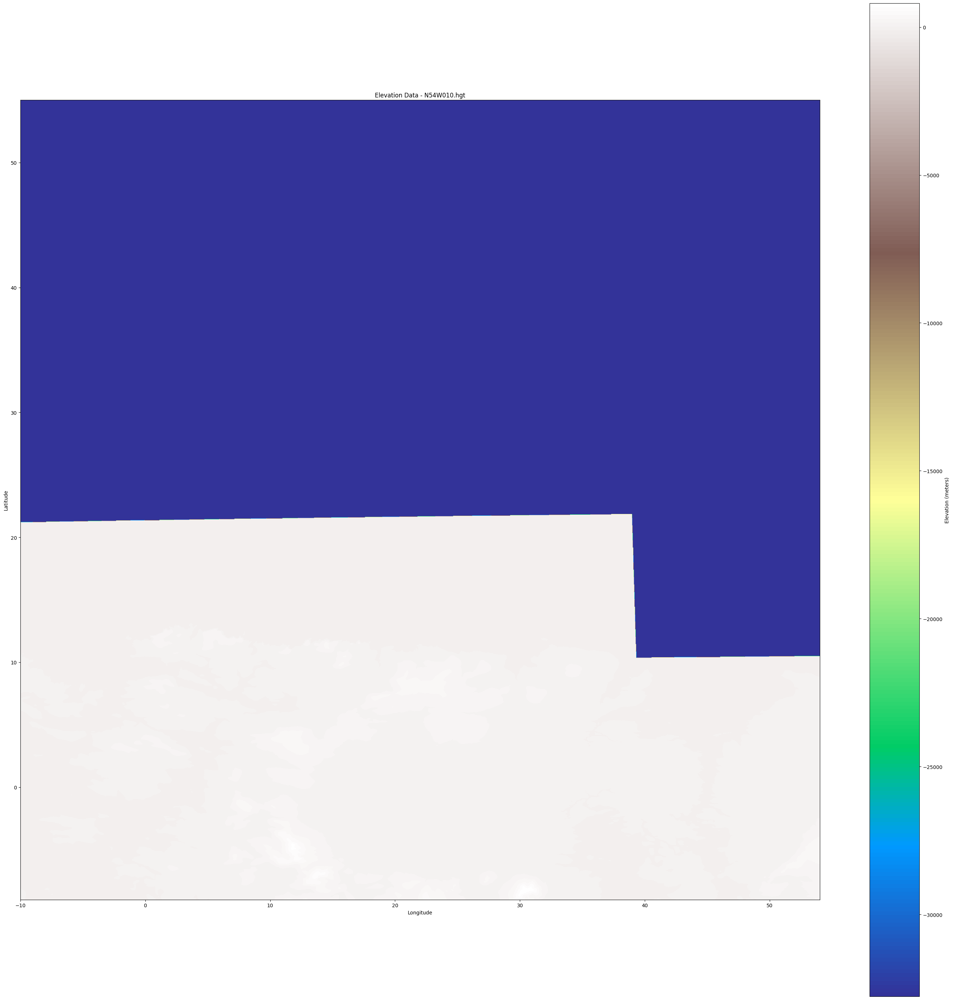

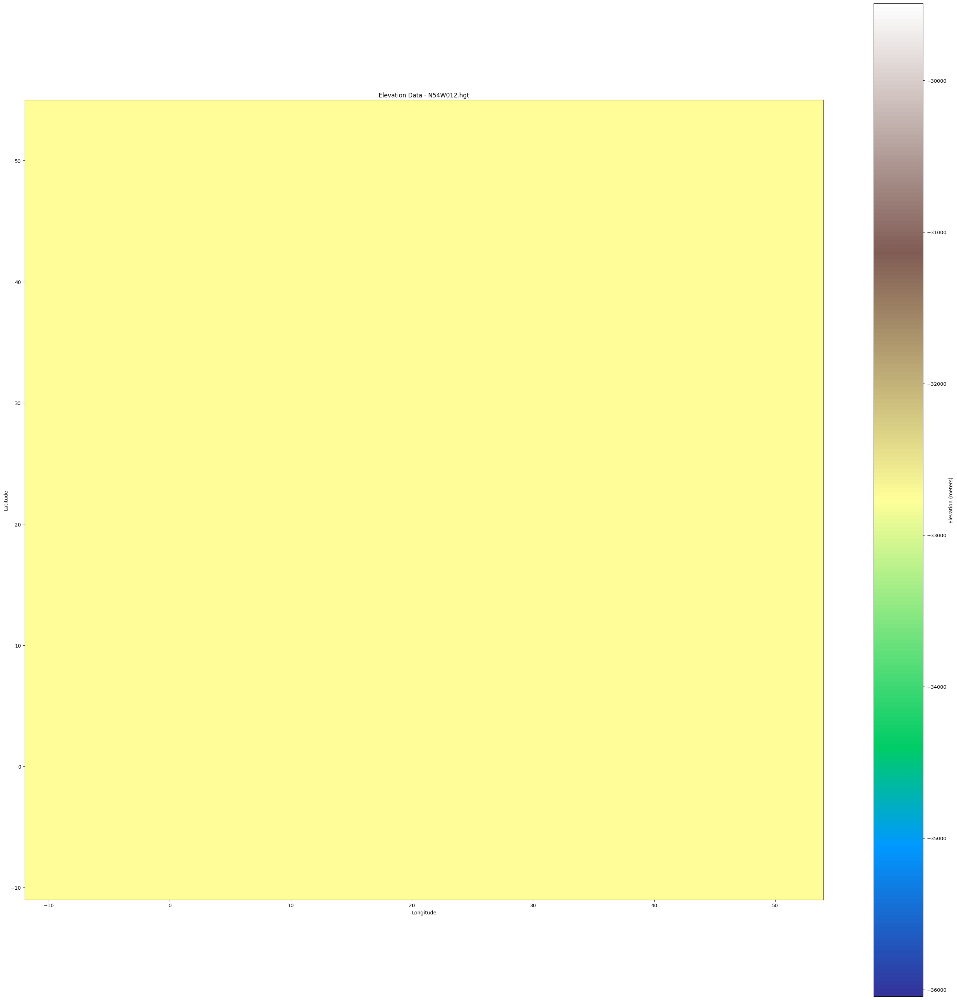

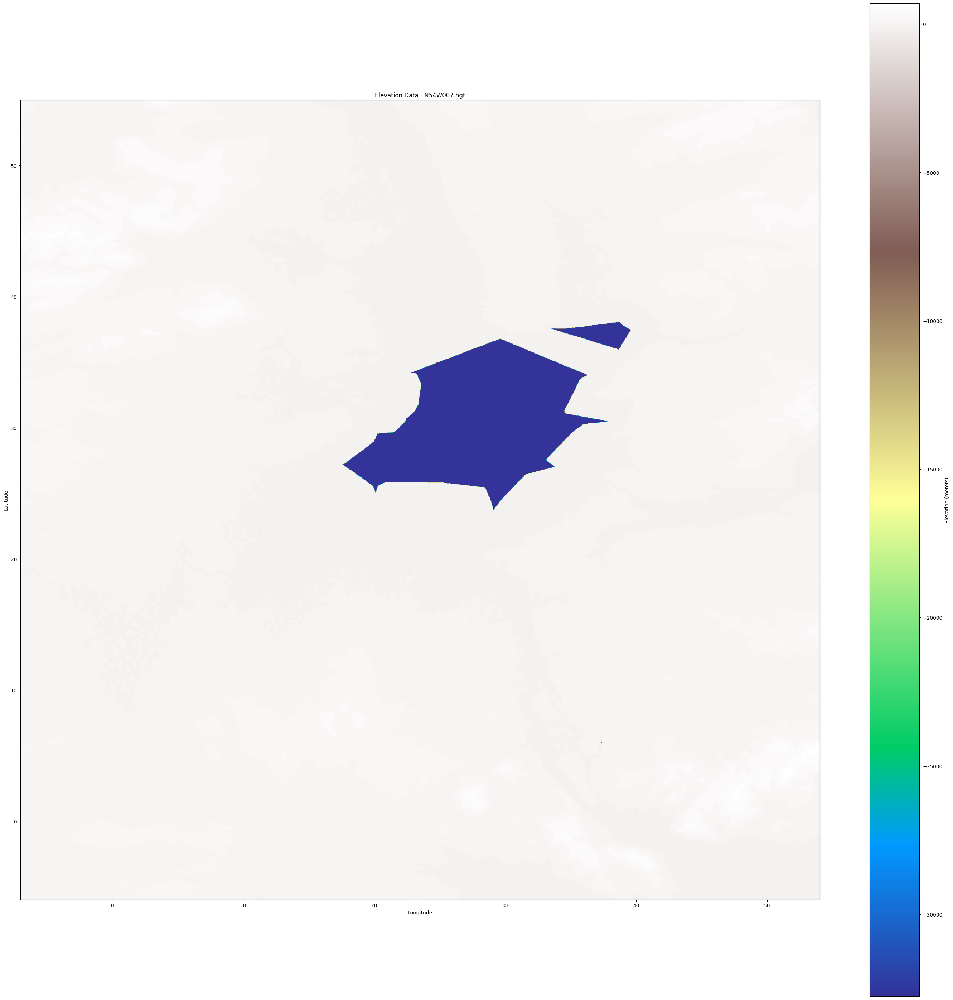

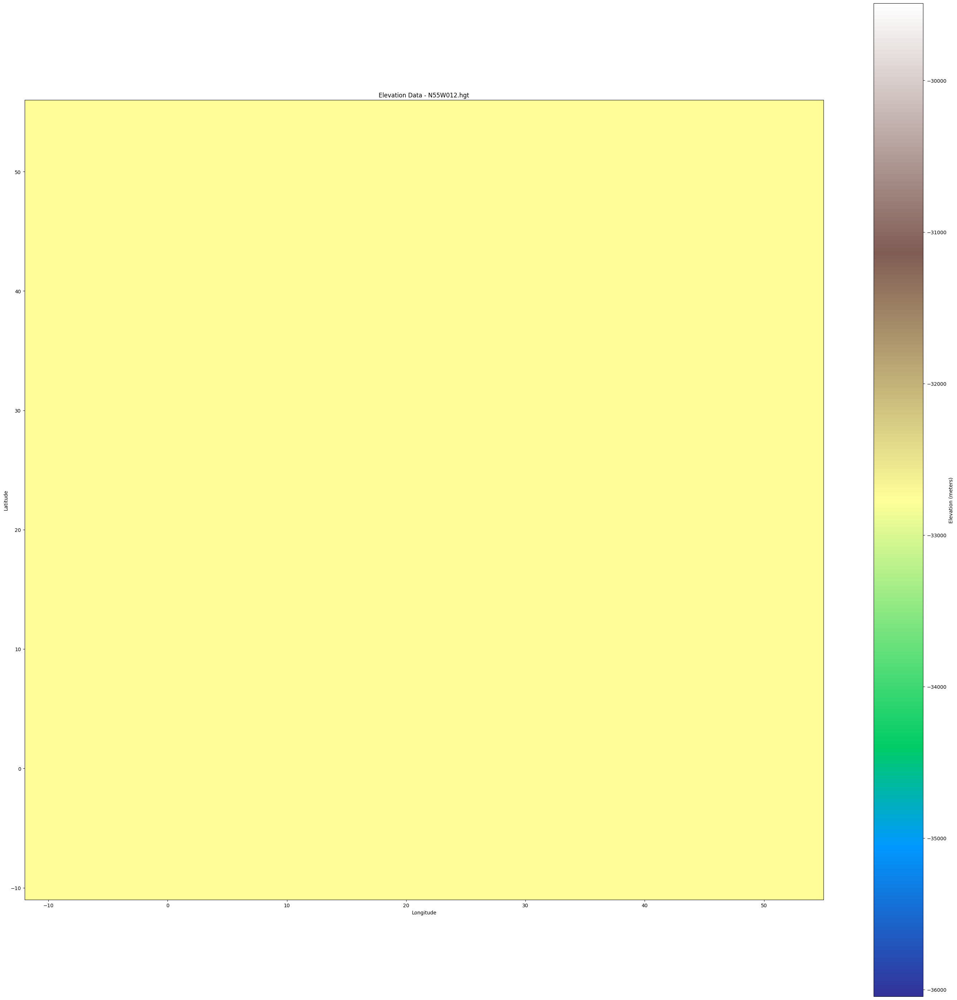

...

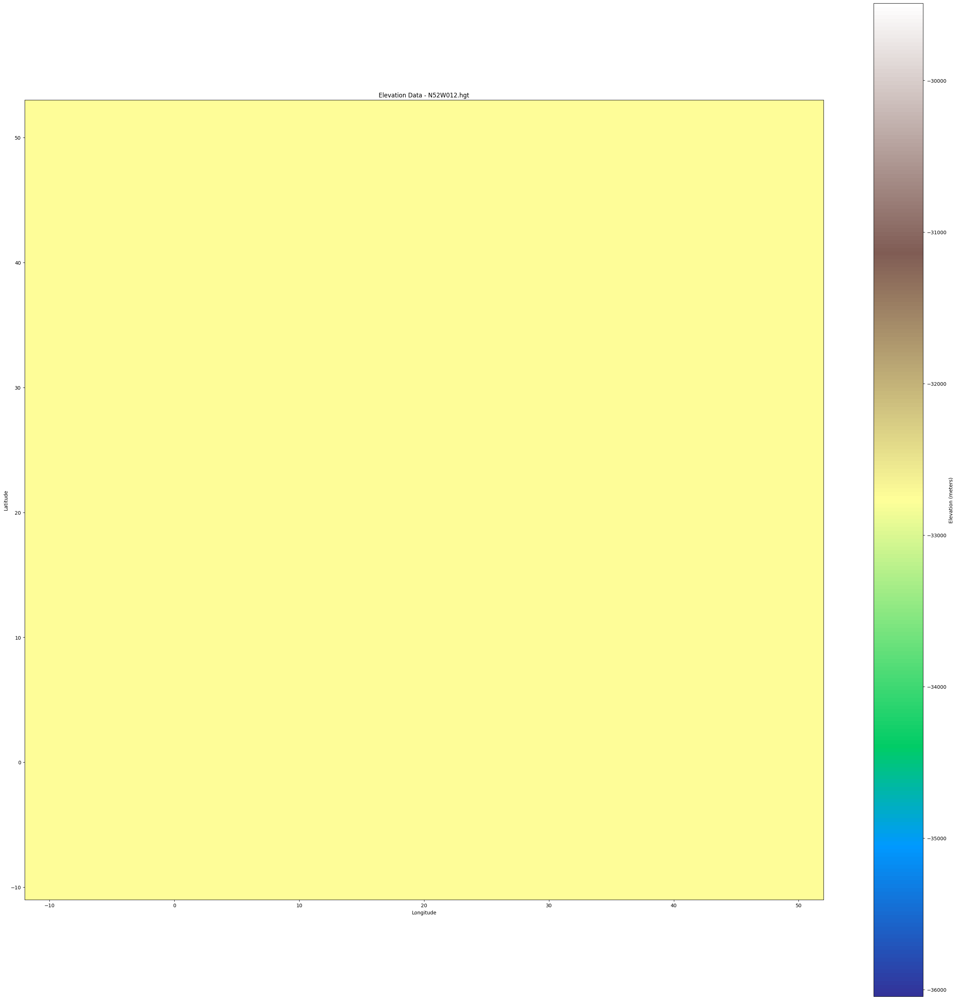

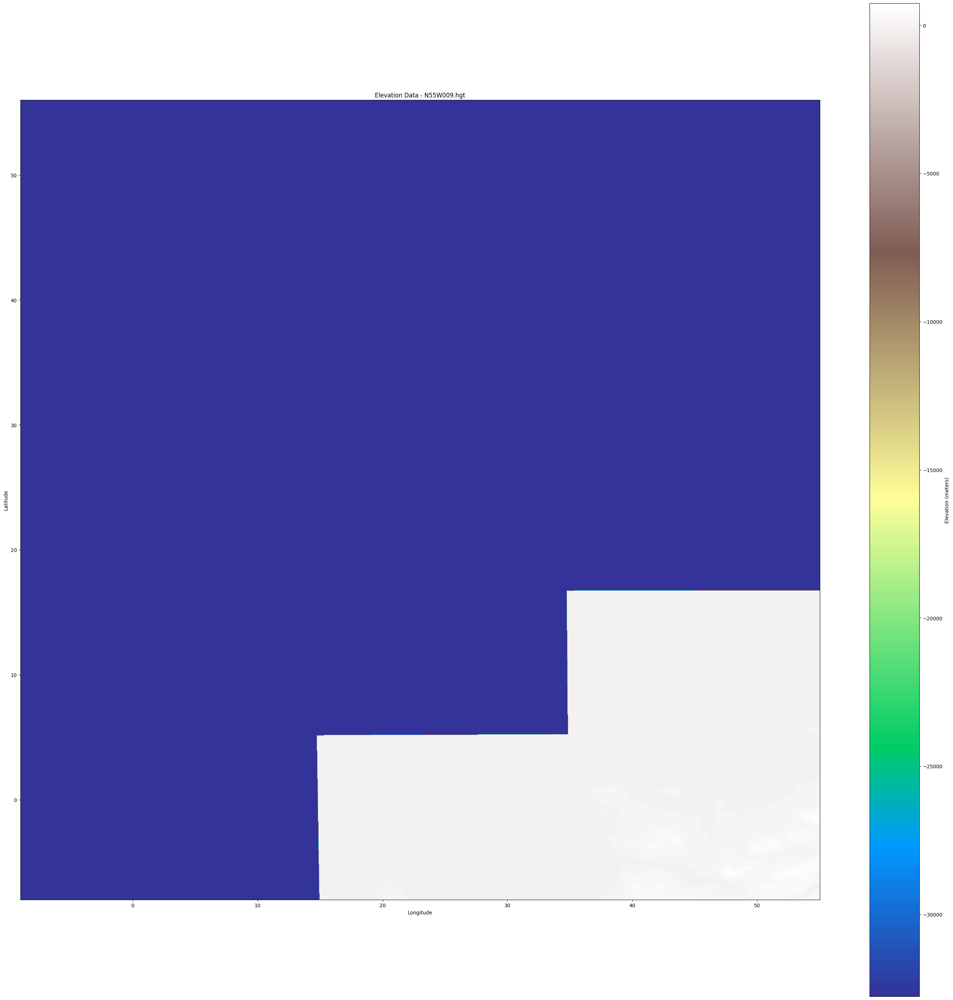

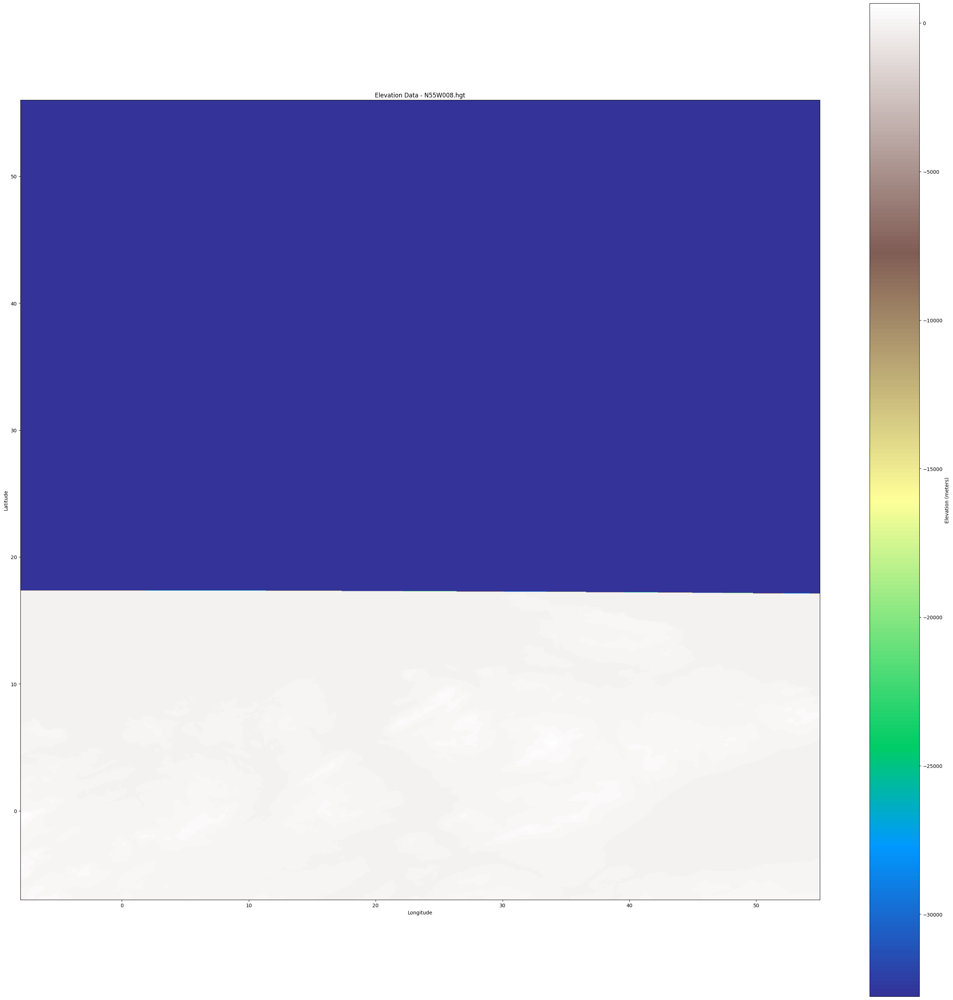

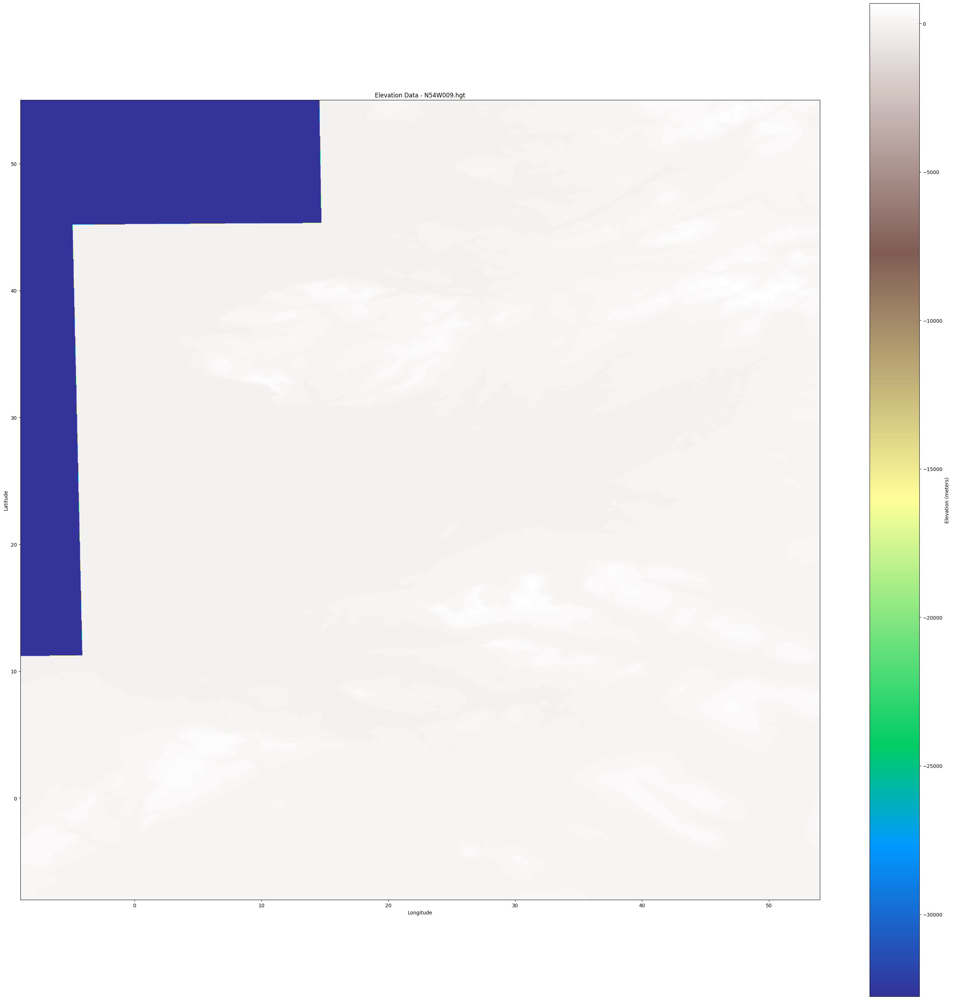

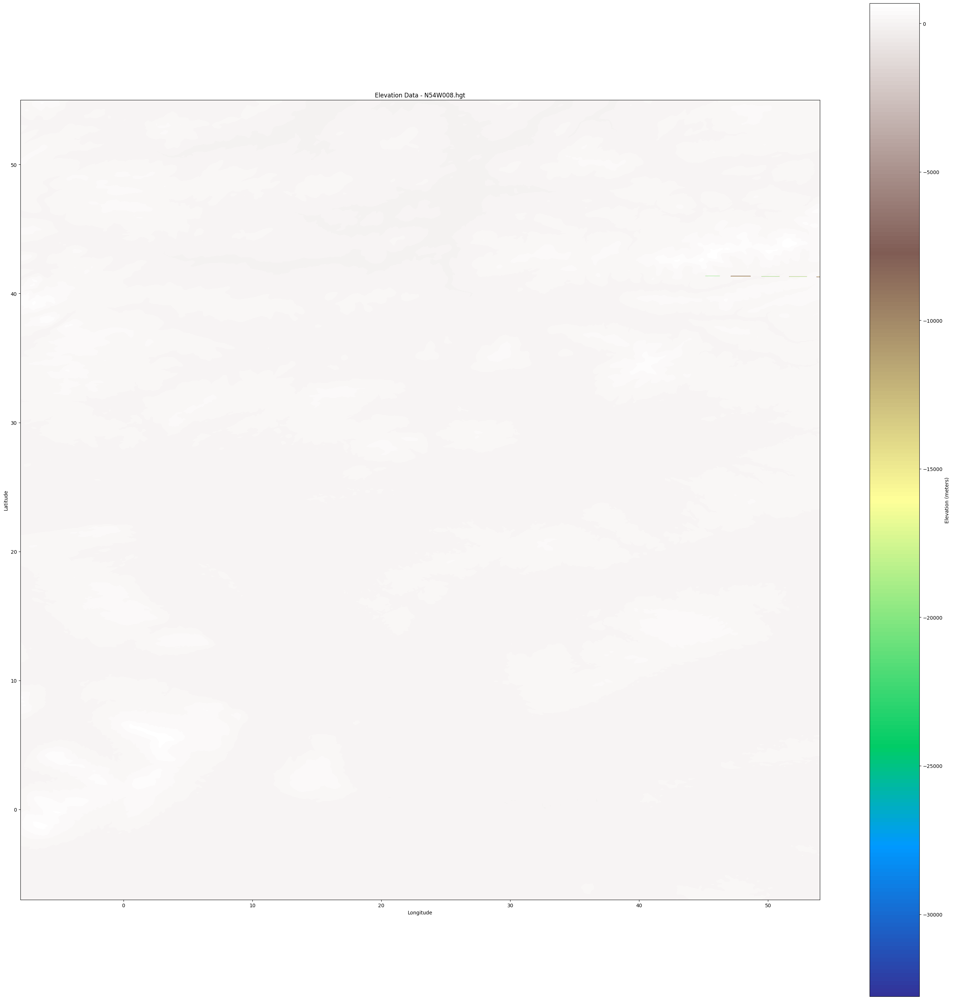

In [104]:
# Iterate over HGT files in the directory

for filename in os.listdir(hgt_directory):
    if filename.endswith(".hgt"):
        hgt_path = os.path.join(hgt_directory, filename)

        # Open the HGT file
        with rasterio.open(hgt_path, 'r') as src:
            # Read the elevation data
            elevation_data = src.read(1)  # Assuming a single band for simplicity

            # Get the width and height of the raster
            width, height = src.width, src.height

            # Plot the elevation data
            plt.figure(figsize=(width / 100, height / 100))  # Adjust the scale factor as needed
            plt.imshow(elevation_data, cmap='terrain', extent=src.bounds, origin='upper')
            plt.title(f'Elevation Data - {filename}')
            plt.colorbar(label='Elevation (meters)')
            plt.xlabel('Longitude')
            plt.ylabel('Latitude')
            plt.show()

(6000, 6000)

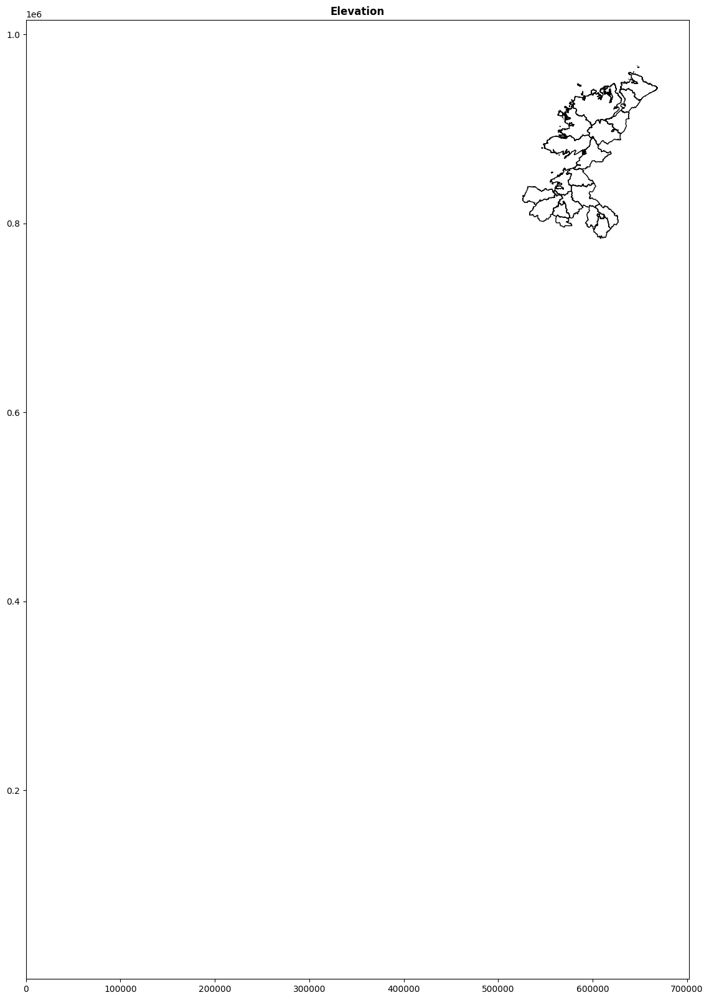

In [75]:
geo_height.crs

CRS.from_epsg(2157)

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [ ]:
class StateVector:
    def __init__(self):
        self.vector = {}


    def add_state(self, t, ra, dec, z_0, object_details, inception_point):
            self.vector[t] = {
                'RA': ra,
                'Dec': dec,
                'z_0': z_0,
                'object_details': object_details,
                'inception_point': inception_point
            }

    def get_state(self, t):
        return self.vector[t]
    

In [ ]:
Cairbre_Drom_cliabh = StateVector()
Cairbre_Drom_cliabh.add_state(t=1, ra=10, dec=20, z_0=423, object_details=baronies_NW, inception_point= None)

timestep = 1  # Choose a specific time step
state_timestep = Cairbre_Drom_cliabh.get_state(timestep)

# Extracting information from the state vector
# Extracting information from the state vector
x_coord = state_timestep['RA']
y_coord = state_timestep['Dec']
z_coord = state_timestep['z_0']
object_details = state_timestep['object_details']


Object Details:
      BY_ID         ENGLISH             GAEILGE LOGAINM_ID        CONTAE  \
12    59008         TIRHUGH           Tír Aodha         52  Dún na nGall   
42   119002      DRUMAHAIRE     Droim Dhá Thiar        137      Liatroim   
94    59005     KILMACRENAN   Cill Mhic Réanáin         55  Dún na nGall   
129  209003          CORRAN           An Corann        229      Sligeach   
141   59001          BANAGH             Báinigh         54  Dún na nGall   
142  209002        COOLAVIN       Cúil Ó bhFinn        228      Sligeach   
144  119003         LEITRIM            Liatroim        135      Liatroim   
161  209005        TIRERAGH      Tír Fhiachrach        230      Sligeach   
173   59003  INISHOWEN EAST  Inis Eoghain Thoir         57  Dún na nGall   
175  119005      ROSCLOGHER        Ros Clochair        138      Liatroim   
199   59007    RAPHOE SOUTH    Ráth Bhoth Theas         59  Dún na nGall   
204   59004  INISHOWEN WEST  Inis Eoghain Thiar         53  Dún na nGall

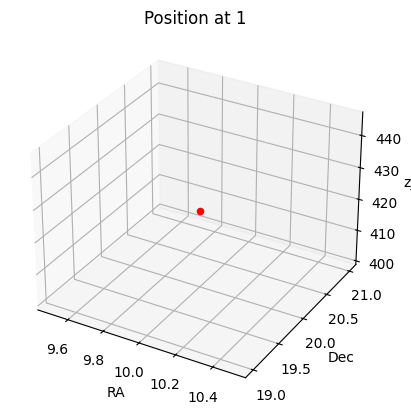

In [ ]:
#Plotting the point
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x_coord, y_coord, z_coord, c='red', marker='o')

ax.set_xlabel('RA')
ax.set_ylabel('Dec')
ax.set_zlabel('z_0')
ax.set_title(f"Position at {timestep}")

# Printing object details
print("Object Details:")
print(object_details)

plt.show()

<bound method DataFrame.info of Empty GeoDataFrame
Columns: [BY_ID, ENGLISH, GAEILGE, LOGAINM_ID, CONTAE, COUNTY, PROVINCE, GUID, CENTROID_X, CENTROID_Y, AREA, OBJECTID, Shape__Are, Shape__Len, geometry]
Index: []>